In [1]:
import pandas as pd
import numpy as np
#loading 3 files from the dataset(lab,dietary excluded)
demo = pd.read_csv('/Users/sana/Documents/sleep disorder project/NHANES_2017-2018/demographics.csv')
exam = pd.read_csv('/Users/sana/Documents/sleep disorder project/NHANES_2017-2018/examination.csv')
ques = pd.read_csv('/Users/sana/Documents/sleep disorder project/NHANES_2017-2018/questionnaire.csv')

In [2]:
demo_cols = ['SEQN', 'RIAGENDR', 'RIDAGEYR', 'DMDEDUC2'] #id,gender,age,education
exam_cols = ['SEQN', 'BMXBMI', 'BMXWT', 'BMXHT', 'BMXWAIST', 'BPXSY1', 'BPXDI1', 'BPXPLS'] #id,BMI, weight, height, waist, systolic BP, diastolic BP, pulse.
ques_cols = ['SEQN', 'SLQ050', 'SLQ030', 'SLQ040', 'SLQ120', 'PAQ605', 'PAQ620', 'SMQ020'] #id,the sleep questions (SLQ050, SLQ030, SLQ040, SLQ120), activity questions (PAQ605, PAQ620), and the smoking question (SMQ020)
# extra SELF-REPORT questions from the same questionnaire file (no lab, no device, no clinic visit needed)
phq8_items = ['DPQ010', 'DPQ020', 'DPQ040', 'DPQ050', 'DPQ060', 'DPQ070', 'DPQ080']  # PHQ-8: DPQ030 (sleep item) left out, it overlaps the target
ques_cols += ['SLD012', 'SLD013', 'HUQ010', 'PAD680'] + phq8_items    # sleep hours wkday/wkend, general health, sitting minutes
#columns to keep

In [3]:
df = demo[demo_cols].merge(exam[exam_cols], on='SEQN', how='inner')
df = df.merge(ques[ques_cols], on='SEQN', how='inner')

#merging

In [4]:
print('after merge:', df.shape)

#shape

after merge: (8704, 29)


In [5]:
df = df[df['SLQ050'].notna()]
print('after dropping no sleep data:', df.shape)
#nan values only for target column

after dropping no sleep data: (5828, 29)


In [6]:
df['SLQ050'] = df['SLQ050'].replace({7: np.nan, 9: np.nan})
df = df[df['SLQ050'].notna()]
df['Doctor_Diagnosed_Sleep_Trouble'] = df['SLQ050'].map({1: 'Yes', 2: 'No'})
# 1 and 2 actual ans remove 7 and 9 

In [7]:
gender_map = {1: 'Male', 2: 'Female'}
df['Gender'] = df['RIAGENDR'].map(gender_map) #convert the codes

In [8]:
educ_map = {1: 'Less than 9th grade', 2: '9-11th grade', 3: 'High school grad/GED',
            4: 'Some college', 5: 'College grad or above'}
df['Education'] = df['DMDEDUC2'].replace({7: np.nan, 9: np.nan}).map(educ_map) #convert the codes

In [9]:
snore_map = {0: 'Never', 1: 'Rarely (1-2 nights/wk)', 2: 'Occasionally (3-4 nights/wk)', 3: 'Frequently (5+ nights/wk)'} #convert the codes

In [10]:
df['Snoring_Frequency'] = df['SLQ030'].replace({7: np.nan, 9: np.nan}).map(snore_map)
#convert the codes

In [11]:
df['Stop_Breathing_Snort_Frequency'] = df['SLQ040'].replace({7: np.nan, 9: np.nan}).map(snore_map) #convert the codes

In [12]:
sleepy_map = {0: 'Never', 1: 'Rarely (1x/month)', 2: 'Sometimes (2-4x/month)',
              3: 'Often (5-15x/month)', 4: 'Almost always (16-30x/month)'}
df['Daytime_Sleepiness_Frequency'] = df['SLQ120'].replace({7: np.nan, 9: np.nan}).map(sleepy_map) #convert the codes

In [13]:
yn_map = {1: 'Yes', 2: 'No'}
df['Vigorous_Work_Activity'] = df['PAQ605'].replace({7: np.nan, 9: np.nan}).map(yn_map)
df['Vigorous_Recreational_Activity'] = df['PAQ620'].replace({7: np.nan, 9: np.nan}).map(yn_map)
df['Smoked_100_Cigarettes_Lifetime'] = df['SMQ020'].replace({7: np.nan, 9: np.nan}).map(yn_map) #convert the codes

In [14]:
# decode the extra self-report questions 
#sleep hours, a depression score, general health and sitting time.
df['Sleep_Hours_Weekday'] = df['SLD012']                      # hours, already numeric
df['Sleep_Hours_Weekend'] = df['SLD013']
df['Sitting_Minutes_Day'] = df['PAD680'].replace({7777: np.nan, 9999: np.nan})
health_map = {1: 'Excellent', 2: 'Very good', 3: 'Good', 4: 'Fair', 5: 'Poor'}
df['General_Health'] = df['HUQ010'].replace({7: np.nan, 9: np.nan}).map(health_map)
# PHQ-8 total (0-21). Only counted when all 7 kept items are answered; DPQ030 (trouble sleeping) is excluded on purpose
df['PHQ8_Score'] = df[phq8_items].replace({7: np.nan, 9: np.nan}).sum(axis=1, min_count=len(phq8_items))

In [15]:
df = df.rename(columns={
    'RIDAGEYR': 'Age_years', 'BMXBMI': 'BMI', 'BMXWT': 'Weight_kg', 'BMXHT': 'Height_cm',
    'BMXWAIST': 'Waist_cm', 'BPXSY1': 'Systolic_BP', 'BPXDI1': 'Diastolic_BP', 'BPXPLS': 'Pulse_rate'
}) #renaming the columns

In [16]:
final_cols = ['SEQN', 'Age_years', 'Gender', 'Education', 'BMI', 'Weight_kg', 'Height_cm', 'Waist_cm',
              'Systolic_BP', 'Diastolic_BP', 'Pulse_rate', 'Snoring_Frequency', 'Stop_Breathing_Snort_Frequency',
              'Daytime_Sleepiness_Frequency', 'Vigorous_Work_Activity', 'Vigorous_Recreational_Activity',
              'Smoked_100_Cigarettes_Lifetime',
              'Sleep_Hours_Weekday', 'Sleep_Hours_Weekend', 'PHQ8_Score', 'General_Health', 'Sitting_Minutes_Day',
              'Doctor_Diagnosed_Sleep_Trouble']

In [17]:
df = df[final_cols]

In [18]:
print('rows before cleaning missing:', len(df))  #before cleaning
print(df.isna().sum()) #missing values
print(df['Doctor_Diagnosed_Sleep_Trouble'].value_counts()) #how many yes or no cases

rows before cleaning missing: 5824
SEQN                                0
Age_years                           0
Gender                              0
Education                         575
BMI                               101
Weight_kg                          91
Height_cm                          91
Waist_cm                          356
Systolic_BP                       658
Diastolic_BP                      658
Pulse_rate                        277
Snoring_Frequency                 431
Stop_Breathing_Snort_Frequency    324
Daytime_Sleepiness_Frequency       12
Vigorous_Work_Activity            301
Vigorous_Recreational_Activity    299
Smoked_100_Cigarettes_Lifetime    295
Sleep_Hours_Weekday                45
Sleep_Hours_Weekend                52
PHQ8_Score                        757
General_Health                      6
Sitting_Minutes_Day               337
Doctor_Diagnosed_Sleep_Trouble      0
dtype: int64
Doctor_Diagnosed_Sleep_Trouble
No     4264
Yes    1560
Name: count, dtype: int

In [19]:
df.to_csv('nhanes_sleep_raw_merged.csv', index=False) #save merged file

In [20]:

import pandas as pd
import numpy as np
import openpyxl #for excel file
from openpyxl.styles import Font, Alignment, PatternFill
from openpyxl.utils import get_column_letter 

In [21]:
df = pd.read_csv('nhanes_sleep_raw_merged.csv')
log = [] #reload

In [22]:
log.append(f"Raw merge of demographics + examination + questionnaire on SEQN, then kept only rows where SLQ050 (sleep trouble question) was answered Yes/No -> {len(df)} rows.")

In [23]:
cat_cols = ['Education', 'Snoring_Frequency', 'Stop_Breathing_Snort_Frequency',
            'Daytime_Sleepiness_Frequency', 'Vigorous_Work_Activity',
            'Vigorous_Recreational_Activity', 'Smoked_100_Cigarettes_Lifetime',
            'General_Health'] #columns with categorial data 

In [24]:
# Missing values are NOT filled here any more. Filling them with the median/mode of ALL rows would let the
# future test rows influence the training data (a small leak). They are now filled inside the model pipeline
# (SimpleImputer, fitted on training folds only), see Part 4.
for c in cat_cols:
    n = df[c].isna().sum()
    if n:
        log.append(f"'{c}': {n} missing values, left as NaN (imputed later from training rows only).") #count missing

In [25]:
num_cols = ['BMI', 'Weight_kg', 'Height_cm', 'Waist_cm', 'Systolic_BP', 'Diastolic_BP', 'Pulse_rate',
            'Sleep_Hours_Weekday', 'Sleep_Hours_Weekend', 'PHQ8_Score', 'Sitting_Minutes_Day']
for c in num_cols:
    n = df[c].isna().sum()
    if n:
        log.append(f"'{c}': {n} missing values, left as NaN (imputed later from training rows only).") #same for numeric

In [26]:

df['Target_Binary'] = df['Doctor_Diagnosed_Sleep_Trouble'].map({'Yes': 1, 'No': 0})
log.append("Added Target_Binary column (Yes=1, No=0).") #numeric version of target column

In [27]:
assert df['Target_Binary'].isna().sum() == 0
counts = df['Doctor_Diagnosed_Sleep_Trouble'].value_counts().to_dict()
log.append(f"Final: {len(df)} rows, {int(df.isna().any(axis=1).sum())} rows with at least one missing feature "
           f"(imputed later inside the pipeline). Class balance: {counts}") #target must be complete

In [28]:
for l in log:
    print(l) #print all log what missing values were filled in with

Raw merge of demographics + examination + questionnaire on SEQN, then kept only rows where SLQ050 (sleep trouble question) was answered Yes/No -> 5824 rows.
'Education': 575 missing values, left as NaN (imputed later from training rows only).
'Snoring_Frequency': 431 missing values, left as NaN (imputed later from training rows only).
'Stop_Breathing_Snort_Frequency': 324 missing values, left as NaN (imputed later from training rows only).
'Daytime_Sleepiness_Frequency': 12 missing values, left as NaN (imputed later from training rows only).
'Vigorous_Work_Activity': 301 missing values, left as NaN (imputed later from training rows only).
'Vigorous_Recreational_Activity': 299 missing values, left as NaN (imputed later from training rows only).
'Smoked_100_Cigarettes_Lifetime': 295 missing values, left as NaN (imputed later from training rows only).
'General_Health': 6 missing values, left as NaN (imputed later from training rows only).
'BMI': 101 missing values, left as NaN (imputed la

In [29]:
guide_rows = [
    ('SEQN', 'Respondent ID, unique per participant'),
    ('Age_years', 'Age in years (RIDAGEYR)'),
    ('Gender', 'Male/Female (RIAGENDR)'),
    ('Education', 'Highest education level completed (DMDEDUC2)'),
    ('BMI', 'Body mass index (BMXBMI)'),
    ('Weight_kg', 'Body weight in kg (BMXWT)'),
    ('Height_cm', 'Standing height in cm (BMXHT)'),
    ('Waist_cm', 'Waist circumference in cm (BMXWAIST)'),
    ('Systolic_BP', 'First systolic blood pressure reading (BPXSY1)'),
    ('Diastolic_BP', 'First diastolic blood pressure reading (BPXDI1)'),
    ('Pulse_rate', '60 sec pulse (BPXPLS)'),
    ('Snoring_Frequency', 'How often participant snores (SLQ030)'),
    ('Stop_Breathing_Snort_Frequency', 'How often participant snorts/stops breathing in sleep (SLQ040)'),
    ('Daytime_Sleepiness_Frequency', 'How often participant feels overly sleepy in daytime (SLQ120)'),
    ('Vigorous_Work_Activity', 'Does vigorous activity at work (PAQ605)'),
    ('Vigorous_Recreational_Activity', 'Does vigorous recreational activity (PAQ620)'),
    ('Smoked_100_Cigarettes_Lifetime', 'Smoked at least 100 cigarettes ever (SMQ020)'),
    ('Sleep_Hours_Weekday', 'Usual hours of sleep on weekdays/workdays (SLD012)'),
    ('Sleep_Hours_Weekend', 'Usual hours of sleep on weekends (SLD013)'),
    ('PHQ8_Score', 'PHQ-8 depression screener total 0-21 (DPQ010-080 without DPQ030, the sleep item)'),
    ('General_Health', 'Self-rated general health, Excellent..Poor (HUQ010)'),
    ('Sitting_Minutes_Day', 'Minutes spent sitting on a typical day (PAD680)'),
    ('Doctor_Diagnosed_Sleep_Trouble', 'TARGET - ever told by doctor had trouble sleeping (SLQ050)'),
    ('Target_Binary', 'Same as above, Yes=1 No=0, for direct model use'),
]
guide = pd.DataFrame(guide_rows, columns=['Column', 'Description']) #build column reference explains what what each column means 

In [30]:
out_path = '/Users/sana/Documents/sleep disorder project/NHANES_Sleep_Dataset_Cleaned_v2.xlsx'
with pd.ExcelWriter(out_path, engine='openpyxl') as writer:
    df.to_excel(writer, sheet_name='Data_Cleaned', index=False)
    guide.to_excel(writer, sheet_name='Column Guide', index=False)
    pd.DataFrame({'Cleaning Step': log}).to_excel(writer, sheet_name='Cleaning Log', index=False)
 
wb = openpyxl.load_workbook(out_path)
header_font = Font(name='Arial', bold=True, color='FFFFFF')
header_fill = PatternFill(start_color='4472C4', end_color='4472C4', fill_type='solid')
body_font = Font(name='Arial', size=10)
for sn in wb.sheetnames:
    ws = wb[sn]
    for cell in ws[1]:
        cell.font = header_font
        cell.fill = header_fill
        cell.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)
    for row in ws.iter_rows(min_row=2):
        for cell in row:
            cell.font = body_font
    for col_cells in ws.columns:
        length = max(len(str(c.value)) if c.value is not None else 0 for c in col_cells)
        col_letter = get_column_letter(col_cells[0].column)
        ws.column_dimensions[col_letter].width = min(max(length + 2, 10), 45)
    ws.freeze_panes = 'A2'
wb.save(out_path)
print('saved', out_path)
 #saves the excel sheet

saved /Users/sana/Documents/sleep disorder project/NHANES_Sleep_Dataset_Cleaned_v2.xlsx


saved eda_overview.png

Doctor_Diagnosed_Sleep_Trouble
No     4264
Yes    1560
Name: count, dtype: int64

Target_Binary          1.000000
PHQ8_Score             0.308530
Waist_cm               0.170067
BMI                    0.150943
Age_years              0.143324
Systolic_BP            0.066566
Diastolic_BP           0.029549
Pulse_rate             0.018843
Sleep_Hours_Weekday   -0.041041
Name: Target_Binary, dtype: float64


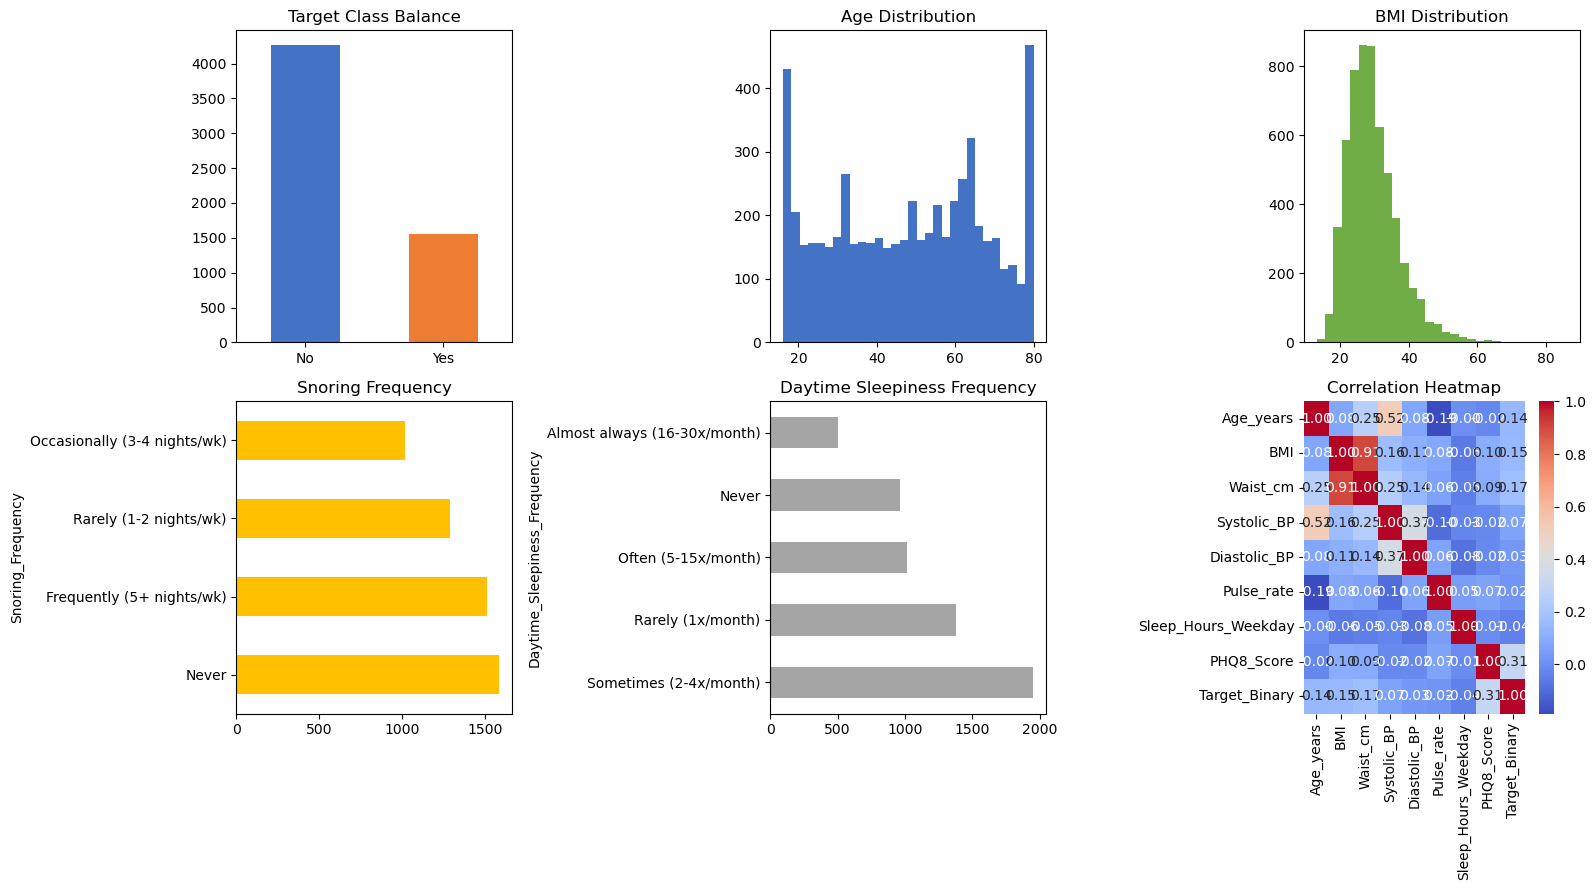

In [31]:
#EDA
#EDA showed that the target classes were imbalanced, and variables such as BMI,
#waist circumference, and age had positive but relatively weak associations with
#the sleep-trouble target. Therefore, we needed a machine-learning approach using 
#multiple features rather than relying on a single variable.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel('/Users/sana/Documents/sleep disorder project/NHANES_Sleep_Dataset_Cleaned_v2.xlsx', sheet_name='Data_Cleaned')

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# class balance
df['Doctor_Diagnosed_Sleep_Trouble'].value_counts().plot(kind='bar', ax=axes[0,0], color=['#4472C4','#ED7D31'])
axes[0,0].set_title('Target Class Balance')
axes[0,0].set_xlabel('')
axes[0,0].tick_params(axis='x', rotation=0)

# age distribution
axes[0,1].hist(df['Age_years'], bins=30, color='#4472C4')
axes[0,1].set_title('Age Distribution')

# bmi distribution
axes[0,2].hist(df['BMI'], bins=30, color='#70AD47')
axes[0,2].set_title('BMI Distribution')

# snoring frequency
df['Snoring_Frequency'].value_counts().plot(kind='barh', ax=axes[1,0], color='#FFC000')
axes[1,0].set_title('Snoring Frequency')

# daytime sleepiness
df['Daytime_Sleepiness_Frequency'].value_counts().plot(kind='barh', ax=axes[1,1], color='#A5A5A5')
axes[1,1].set_title('Daytime Sleepiness Frequency')

# correlation heatmap
num_cols = ['Age_years','BMI','Waist_cm','Systolic_BP','Diastolic_BP','Pulse_rate','Sleep_Hours_Weekday','PHQ8_Score','Target_Binary']
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1,2])
axes[1,2].set_title('Correlation Heatmap')

plt.tight_layout()
plt.savefig('eda_overview.png', dpi=150)
print('saved eda_overview.png')

print()
print(df['Doctor_Diagnosed_Sleep_Trouble'].value_counts())
print()
print(corr['Target_Binary'].sort_values(ascending=False))

In [32]:
from IPython.display import Markdown, display
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestCentroid
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import chi2_contingency

In [33]:
snore_map = {'Never': 0, 'Rarely (1-2 nights/wk)': 1, 'Occasionally (3-4 nights/wk)': 2, 'Frequently (5+ nights/wk)': 3}
sleepy_map = {'Never': 0, 'Rarely (1x/month)': 1, 'Sometimes (2-4x/month)': 2, 'Often (5-15x/month)': 3, 'Almost always (16-30x/month)': 4}
yn_map = {'No': 0, 'Yes': 1}

# clustering uses the same 12 body / symptom / lifestyle profile variables as before (the new questionnaire items are only used by the classifiers)
cluster_features = ['Age_years', 'BMI', 'Waist_cm', 'Systolic_BP', 'Diastolic_BP', 'Pulse_rate'] #select features for clusters
X_cluster = df[cluster_features].copy()
X_cluster['Snoring_Frequency'] = df['Snoring_Frequency'].map(snore_map)
X_cluster['Stop_Breathing_Snort_Frequency'] = df['Stop_Breathing_Snort_Frequency'].map(snore_map)
X_cluster['Daytime_Sleepiness_Frequency'] = df['Daytime_Sleepiness_Frequency'].map(sleepy_map)
X_cluster['Vigorous_Work_Activity'] = df['Vigorous_Work_Activity'].map(yn_map)
X_cluster['Vigorous_Recreational_Activity'] = df['Vigorous_Recreational_Activity'].map(yn_map)
X_cluster['Smoked_100_Cigarettes_Lifetime'] = df['Smoked_100_Cigarettes_Lifetime'].map(yn_map)

# exploratory (descriptive) clustering on all rows: median-fill then standardise. Part 4 re-does this on training rows only.
X_scaled = StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(X_cluster)) #clusters without target 

k=2  silhouette=0.140  merge height to go from 2 to 1 clusters=118.1


k=3  silhouette=0.102  merge height to go from 3 to 2 clusters=112.9


k=4  silhouette=0.107  merge height to go from 4 to 3 clusters=82.9


k=5  silhouette=0.103  merge height to go from 5 to 4 clusters=66.9


k=6  silhouette=0.082  merge height to go from 6 to 5 clusters=59.5


k=7  silhouette=0.087  merge height to go from 7 to 6 clusters=55.8


k=8  silhouette=0.092  merge height to go from 8 to 7 clusters=54.5


saved dendrogram_silhouette.png


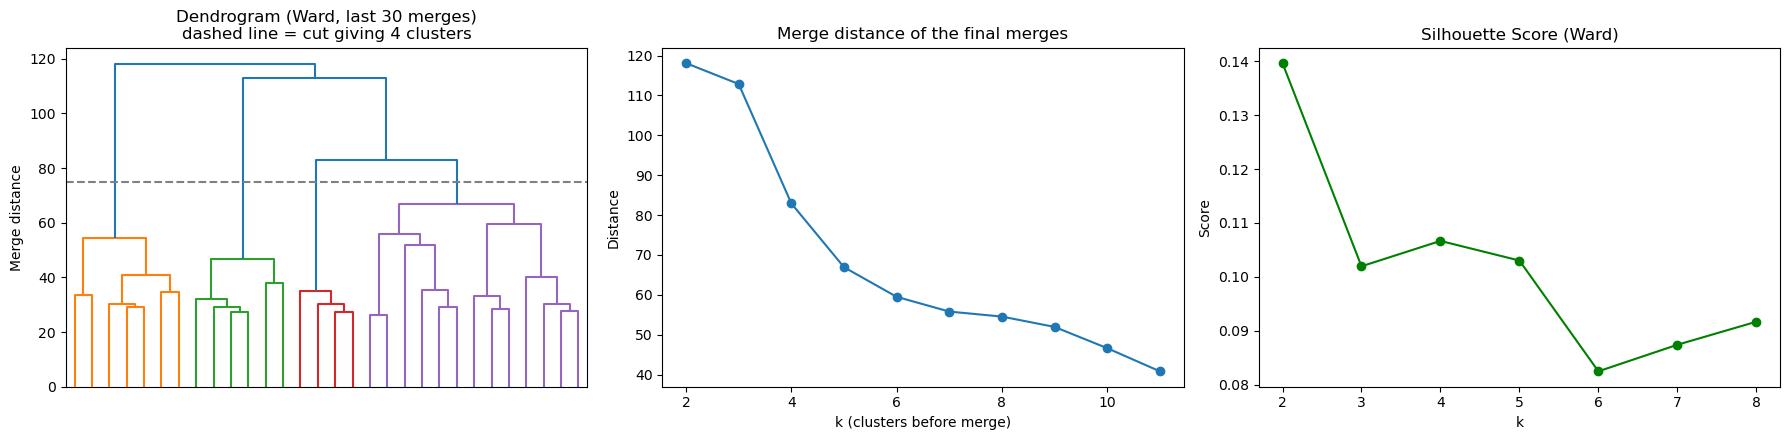

In [34]:
# Choosing k for hierarchical (Ward) clustering: dendrogram + merge-distance jumps + silhouette
Z = linkage(X_scaled, method='ward')            # full merge tree (Ward = merge the pair that increases within-cluster variance the least)
merge_heights = Z[::-1, 2][:10]                 # height of the last 10 merges -> a big jump means a natural cut
sil_scores = []
k_range = range(2, 9)
for k in k_range:
    labels_test = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, labels_test))
    print(f'k={k}  silhouette={sil_scores[-1]:.3f}  merge height to go from {k} to {k-1} clusters={merge_heights[k-2]:.1f}')

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
dendrogram(Z, truncate_mode='lastp', p=30, ax=ax[0], no_labels=True, color_threshold=(Z[-4, 2] + Z[-3, 2]) / 2)
ax[0].axhline((Z[-4, 2] + Z[-3, 2]) / 2, ls='--', c='grey'); ax[0].set_title('Dendrogram (Ward, last 30 merges)\ndashed line = cut giving 4 clusters'); ax[0].set_ylabel('Merge distance')
ax[1].plot(list(range(2, 12)), merge_heights, marker='o')
ax[1].set_title('Merge distance of the final merges'); ax[1].set_xlabel('k (clusters before merge)'); ax[1].set_ylabel('Distance')
ax[2].plot(list(k_range), sil_scores, marker='o', color='green')
ax[2].set_title('Silhouette Score (Ward)'); ax[2].set_xlabel('k'); ax[2].set_ylabel('Score')
plt.tight_layout()
plt.savefig('dendrogram_silhouette.png', dpi=150)
print('saved dendrogram_silhouette.png') #dendrogram + silhouette to decide how many

**Why hierarchical clustering:** the 12 profile variables mix continuous measurements with ordinal and yes/no answers, and K-Means assumes round, equally sized groups around a mean. Agglomerative (Ward) clustering builds a full merge tree, lets us *see* the cluster structure in a dendrogram before choosing k, and does not depend on a random start. K-Means and GMM are kept only as comparison methods in the validation table.

*Choice of k = 4: silhouette is highest at k = 2 (0.14), but that split mainly separates younger from older people and gives no usable risk profiles. For k = 3-8 the silhouette is highest at k = 4 (0.107), and in the dendrogram the 4-cluster cut sits above a clear gap (merge distance 83 vs 67 for the next merge). k = 4 is therefore used for interpretability; the low silhouette at every k shows the groups overlap. Cluster names are given after the profile table below. The labels used for classification in Part 4 are re-fitted on training rows only, so cluster ids there may be numbered differently.*

In [35]:
hier = AgglomerativeClustering(n_clusters=4, linkage='ward')
df['Cluster'] = hier.fit_predict(X_scaled)

profile = df.groupby('Cluster').agg(
    Count=('SEQN', 'count'),
    Avg_Age=('Age_years', 'mean'),
    Avg_BMI=('BMI', 'mean'),
    Avg_Waist=('Waist_cm', 'mean'),
    Avg_Systolic_BP=('Systolic_BP', 'mean'),
    Snoring=('Snoring_Frequency', lambda s: s.map(snore_map).mean()),
    Daytime_Sleepy=('Daytime_Sleepiness_Frequency', lambda s: s.map(sleepy_map).mean()),
    Smoked=('Smoked_100_Cigarettes_Lifetime', lambda s: s.map(yn_map).mean()),
    Sleep_Trouble_Rate=('Target_Binary', 'mean')
).round(2)
print('\nCluster profile (hierarchical, Ward):')
print(profile) #apply hierarchical clustering and place people into clusters 


Cluster profile (hierarchical, Ward):
         Count  Avg_Age  Avg_BMI  Avg_Waist  Avg_Systolic_BP  Snoring  \
Cluster                                                                 
0         2553    58.48    30.87     104.28           132.56     1.63   
1         1255    44.26    30.26     101.62           124.54     1.61   
2         1486    31.37    25.25      86.01           111.21     0.61   
3          530    54.37    32.68     108.00           130.42     2.58   

         Daytime_Sleepy  Smoked  Sleep_Trouble_Rate  
Cluster                                              
0                  1.68    0.46                0.28  
1                  1.86    0.47                0.27  
2                  1.74    0.17                0.17  
3                  2.15    0.52                0.46  




Cluster	Who they are

0	Older, higher blood pressure	

1	Middle-aged, overweight	

2	Young, healthy weight, few symptoms	

3	Heavy snorers, highest BMI, sleepy in the day	



saved cluster_risk_rates.png


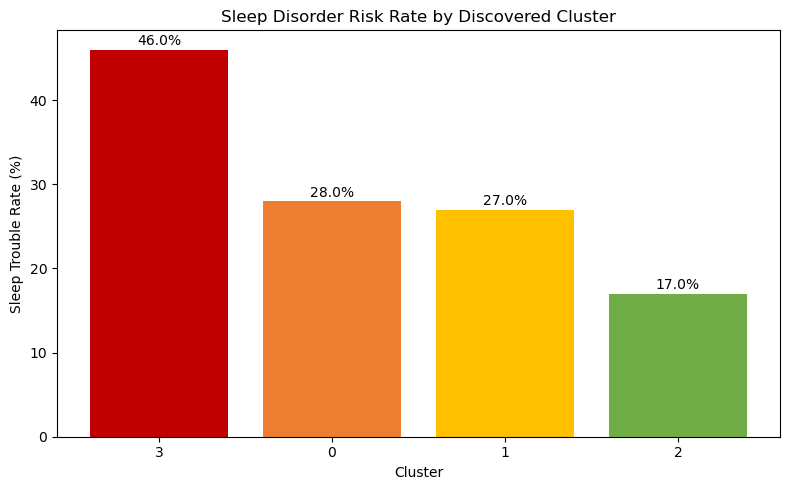

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))
rates = profile['Sleep_Trouble_Rate'].sort_values(ascending=False) * 100
bars = ax.bar(rates.index.astype(str), rates, color=['#C00000', '#ED7D31', '#FFC000', '#70AD47'])
ax.set_xlabel('Cluster')
ax.set_ylabel('Sleep Trouble Rate (%)')
ax.set_title('Sleep Disorder Risk Rate by Discovered Cluster')
for bar, rate in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{rate:.1f}%', ha='center')
plt.tight_layout()
plt.savefig('cluster_risk_rates.png', dpi=150) 
print('saved cluster_risk_rates.png') # chart based on clusters 

In [37]:
ct = pd.crosstab(df['Cluster'], df['Doctor_Diagnosed_Sleep_Trouble'])
chi2, p_val, dof, expected = chi2_contingency(ct)
print(f'\nChi-square test: chi2={chi2:.2f}, p-value={p_val:.2e}')
print('-> p < 0.05 means the clusters are genuinely linked to sleep trouble, not random noise')

df.to_csv('nhanes_with_clusters.csv', index=False)
print('\nsaved nhanes_with_clusters.csv') # cluster validation setup 


Chi-square test: chi2=186.92, p-value=2.82e-40
-> p < 0.05 means the clusters are genuinely linked to sleep trouble, not random noise



saved nhanes_with_clusters.csv



 PART 2: CLUSTER VALIDATION (EXTENDED)


To confirm the hierarchical clusters are genuine and stable, we run independent checks: Silhouette Score, a Chi-square test against the sleep disorder outcome, and agreement (Adjusted Rand Index) with **two** other clustering methods (K-Means and GMM). Results are summarized in one table below.

In [38]:
sil_hier = silhouette_score(X_scaled, df['Cluster'])

km = KMeans(n_clusters=4, random_state=42, n_init=10)
km_labels = km.fit_predict(X_scaled)
ari_kmeans = adjusted_rand_score(df['Cluster'], km_labels)
sil_kmeans = silhouette_score(X_scaled, km_labels)

gmm = GaussianMixture(n_components=4, random_state=42, n_init=5)
gmm_labels = gmm.fit_predict(X_scaled)
ari_gmm = adjusted_rand_score(df['Cluster'], gmm_labels)

ct = pd.crosstab(df['Cluster'], df['Doctor_Diagnosed_Sleep_Trouble'])
chi2, p_val, dof, expected = chi2_contingency(ct)
rates = df.groupby('Cluster')['Target_Binary'].mean()

validation_summary = pd.DataFrame([
    {'Check': 'Silhouette Score (Hierarchical, Ward)', 'Value': round(sil_hier, 4), 'Interpretation': 'Cluster separation quality'},
    {'Check': 'Silhouette Score (K-Means, comparison)', 'Value': round(sil_kmeans, 4), 'Interpretation': 'Separation, 2nd method'},
    {'Check': 'Chi-square p-value', 'Value': f'{p_val:.2e}', 'Interpretation': 'Link to sleep disorder (significant if <0.05)'},
    {'Check': 'Sleep-trouble rate range across clusters', 'Value': f'{rates.min():.1%} - {rates.max():.1%}', 'Interpretation': 'How different the risk profiles are'},
    {'Check': 'ARI: Hierarchical vs K-Means', 'Value': round(ari_kmeans, 4), 'Interpretation': 'Agreement with 2nd method'},
    {'Check': 'ARI: Hierarchical vs GMM', 'Value': round(ari_gmm, 4), 'Interpretation': 'Agreement with 3rd method'},
])
validation_summary.to_csv('validation_summary.csv', index=False)
validation_summary # We checked our clusters using different methods

,Check,Value,Interpretation
0,"Silhouette Score (Hierarchical, Ward)",0.1067,Cluster separation quality
1,"Silhouette Score (K-Means, comparison)",0.1312,"Separation, 2nd method"
2,Chi-square p-value,2.82e-40,Link to sleep disorder (significant if <0.05)
3,Sleep-trouble rate range across clusters,16.6% - 46.4%,How different the risk profiles are
4,ARI: Hierarchical vs K-Means,0.5171,Agreement with 2nd method
5,ARI: Hierarchical vs GMM,0.466,Agreement with 3rd method


In [39]:
display(Markdown(f"""**Interpretation (generated from the table, read with care):**
- **Chi-square (p = {p_val:.1e}):** clusters are significantly associated with sleep trouble; the sleep-trouble rate ranges from {rates.min():.0%} to {rates.max():.0%} across clusters. This is expected and is not by itself proof that the clusters are "real": age, BMI and waist (which are in the clustering features) already correlate with the target, and with ~5,800 rows even small associations give tiny p-values.
- **Silhouette ({sil_hier:.2f} hierarchical, {sil_kmeans:.2f} K-Means):** *weak* separation. The groups overlap heavily, which is common in survey data.
- **ARI ({ari_kmeans:.2f} vs K-Means, {ari_gmm:.2f} vs GMM):** agreement with other methods; values well above 0 mean the groupings are partly method-independent, not sharply stable.

So the clusters are best described as **useful, overlapping risk profiles**, not sharply separated natural groups."""))

**Interpretation (generated from the table, read with care):**
- **Chi-square (p = 2.8e-40):** clusters are significantly associated with sleep trouble; the sleep-trouble rate ranges from 17% to 46% across clusters. This is expected and is not by itself proof that the clusters are "real": age, BMI and waist (which are in the clustering features) already correlate with the target, and with ~5,800 rows even small associations give tiny p-values.
- **Silhouette (0.11 hierarchical, 0.13 K-Means):** *weak* separation. The groups overlap heavily, which is common in survey data.
- **ARI (0.52 vs K-Means, 0.47 vs GMM):** agreement with other methods; values well above 0 mean the groupings are partly method-independent, not sharply stable.

So the clusters are best described as **useful, overlapping risk profiles**, not sharply separated natural groups.


PART 3: FEATURE PREPARATION


In [40]:
gender_map = {'Male': 0, 'Female': 1}
educ_map = {'Less than 9th grade': 0, '9-11th grade': 1, 'High school grad/GED': 2,
            'Some college': 3, 'College grad or above': 4}
snore_map2 = {'Never': 0, 'Rarely (1-2 nights/wk)': 1, 'Occasionally (3-4 nights/wk)': 2, 'Frequently (5+ nights/wk)': 3}
sleepy_map2 = {'Never': 0, 'Rarely (1x/month)': 1, 'Sometimes (2-4x/month)': 2, 'Often (5-15x/month)': 3, 'Almost always (16-30x/month)': 4}
yn_map2 = {'No': 0, 'Yes': 1}
health_map2 = {'Excellent': 1, 'Very good': 2, 'Good': 3, 'Fair': 4, 'Poor': 5}

df['Gender_enc'] = df['Gender'].map(gender_map)
df['Education_enc'] = df['Education'].map(educ_map)
df['Snoring_enc'] = df['Snoring_Frequency'].map(snore_map2)
df['StopBreathing_enc'] = df['Stop_Breathing_Snort_Frequency'].map(snore_map2)
df['DaytimeSleepy_enc'] = df['Daytime_Sleepiness_Frequency'].map(sleepy_map2)
df['WorkActivity_enc'] = df['Vigorous_Work_Activity'].map(yn_map2)
df['RecActivity_enc'] = df['Vigorous_Recreational_Activity'].map(yn_map2)
df['Smoked_enc'] = df['Smoked_100_Cigarettes_Lifetime'].map(yn_map2)
df['GenHealth_enc'] = df['General_Health'].map(health_map2)

original_features = ['Age_years', 'Gender_enc', 'Education_enc', 'BMI', 'Waist_cm',
                     'Systolic_BP', 'Diastolic_BP', 'Pulse_rate',
                     'Snoring_enc', 'StopBreathing_enc', 'DaytimeSleepy_enc',
                     'WorkActivity_enc', 'RecActivity_enc', 'Smoked_enc']
selfreport_features = ['Sleep_Hours_Weekday', 'Sleep_Hours_Weekend', 'PHQ8_Score', 'GenHealth_enc',
                       'Sitting_Minutes_Day']
base_features = original_features + selfreport_features

# NaN is allowed here: missing values are filled inside the pipeline (training folds only)
print(f'{len(base_features)} features ({len(original_features)} original + {len(selfreport_features)} self-report).')
print('Missing share per feature (filled later from training rows only):')
print(df[base_features].isna().mean().round(3)[lambda s: s > 0].to_string())
df.to_csv('nhanes_encoded.csv', index=False)
pd.DataFrame({'Feature': base_features}).T

#feature prep for ml

19 features (14 original + 5 self-report).
Missing share per feature (filled later from training rows only):
Education_enc          0.099
BMI                    0.017
Waist_cm               0.061
Systolic_BP            0.113
Diastolic_BP           0.113
Pulse_rate             0.048
Snoring_enc            0.074
StopBreathing_enc      0.056
DaytimeSleepy_enc      0.002
WorkActivity_enc       0.052
RecActivity_enc        0.051
Smoked_enc             0.051
Sleep_Hours_Weekday    0.008
Sleep_Hours_Weekend    0.009
PHQ8_Score             0.130
GenHealth_enc          0.001
Sitting_Minutes_Day    0.058


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
Feature,Age_years,Gender_enc,Education_enc,BMI,Waist_cm,Systolic_BP,Diastolic_BP,Pulse_rate,Snoring_enc,StopBreathing_enc,DaytimeSleepy_enc,WorkActivity_enc,RecActivity_enc,Smoked_enc,Sleep_Hours_Weekday,Sleep_Hours_Weekend,PHQ8_Score,GenHealth_enc,Sitting_Minutes_Day


**Why the new features keep this a low-cost screening tool.** Every added feature is a self-reported answer from the same NHANES questionnaire file; none needs a blood test, a sleep study, a device or a clinic visit:

| Feature | Question asked |
|---|---|
| Sleep hours (weekday, weekend) | "How much sleep do you usually get?" |
| PHQ-8 score | the standard 8-item depression screener (free, self-completed). The PHQ-9 sleep item (DPQ030, "trouble falling or staying asleep") is **deliberately left out**, because it is almost the same as the target question and would leak the answer |
| General health | "Would you say your health in general is excellent ... poor?" |
| Sitting minutes | "How much time do you usually spend sitting on a typical day?" |

The body measurements (BMI, waist, blood pressure, pulse) can be taken with a scale, a tape and a home BP cuff, as before. Laboratory and dietary files are still not used.

PART 4: COMPARISON STUDY (CORE RESEARCH QUESTION)

**Research Question:** does adding cluster information before classification improve sleep-trouble prediction, compared to classifying directly?

All three approaches are run under **identical conditions**: same 80/20 stratified split, same 7 models, same hyper-parameter grids, same 5-fold CV, and the same imputation + scaling + SMOTE. Imputation, scaling and SMOTE are applied **inside** each CV fold (training folds only), so neither fill values nor synthetic samples leak into a validation fold. Cluster labels are fitted on **training rows only**.

| Approach | Description |
|---|---|
| **A: Direct Classification** | Base features only |
| **B: Cluster-then-Classify** | Base features + cluster label (one-hot, 4 columns) |
| **C: Per-Cluster Models** | A separate copy of each of the 7 models trained inside each of the 4 clusters (base features only) |

**Primary metric: accuracy** (chosen for comparability with published work). Because ~73% of participants are negative, F1, recall, balanced accuracy and ROC-AUC are reported alongside it, and a majority-class baseline is shown.

**Decision threshold:** SMOTE balances the training data, which makes every model predict "Yes" more often than the real 27% rate. With accuracy as the primary metric the default 0.5 cut-off is therefore too low. For every model the cut-off is tuned on *out-of-fold training predictions* (never on the test set) to maximise the CV score, then applied once to the test set. This raises accuracy at the cost of some recall; both are reported.

**Model selection rule (no test-set peeking):** inside each approach the "best" model is the one with the highest cross-validated score (`SCORING`, set in 4.1, measured at the tuned threshold) on the *training* data. Test-set metrics are reported, never used to choose.


In [41]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix, balanced_accuracy_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from IPython.display import display
import warnings, pickle
warnings.filterwarnings('ignore')

y = df['Target_Binary']
idx_train, idx_test = train_test_split(df.index, test_size=0.2, random_state=42, stratify=y)
with open('split_idx.pkl', 'wb') as f:
    pickle.dump((idx_train, idx_test), f)

split_summary = pd.DataFrame([
    {'Set': 'Train', 'N': len(idx_train), 'Sleep_Trouble_Rate': round(y.loc[idx_train].mean(),3)},
    {'Set': 'Test', 'N': len(idx_test), 'Sleep_Trouble_Rate': round(y.loc[idx_test].mean(),3)},
])
split_summary # 80-20

,Set,N,Sleep_Trouble_Rate
0,Train,4659,0.268
1,Test,1165,0.268


**Leak-free cluster labels for classification.** The clusters from Parts 1-2 were fitted on all rows, including future test rows. For the comparison, missing-value filling, scaling and hierarchical (Ward) clustering are re-fitted on the training rows only. Hierarchical clustering has no `predict()` for new people, so each test row is assigned to the nearest training-cluster centre (`NearestCentroid`), exactly as a new patient would be at screening time.

In [42]:
# Cluster labels used for CLASSIFICATION must not "see" the test rows.
# Parts 1-2 clustered all rows (fine for description). Here imputer + scaler + Ward clustering are re-fitted on TRAIN rows only,
# and test rows are assigned to the nearest train-cluster centroid.
df['Cluster_full_data'] = df['Cluster']                       # exploratory labels kept for reference
clu_imputer = SimpleImputer(strategy='median').fit(X_cluster.loc[idx_train])
clu_scaler = StandardScaler().fit(clu_imputer.transform(X_cluster.loc[idx_train]))
Z_train = clu_scaler.transform(clu_imputer.transform(X_cluster.loc[idx_train]))
Z_all = clu_scaler.transform(clu_imputer.transform(X_cluster))
hc_train = AgglomerativeClustering(n_clusters=4, linkage='ward').fit(Z_train)
assigner = NearestCentroid().fit(Z_train, hc_train.labels_)
df['Cluster'] = assigner.predict(Z_all)                       # test rows: nearest training centroid
df.loc[idx_train, 'Cluster'] = hc_train.labels_               # training rows keep their own hierarchical label
print('Train rows: agreement of Ward labels with nearest-centroid assignment (sanity check):',
      round((assigner.predict(Z_train) == hc_train.labels_).mean(), 3))
print('Agreement between full-data and train-only cluster labels (ARI):',
      round(adjusted_rand_score(df['Cluster_full_data'], df['Cluster']), 3))

# cluster id is a category, not an ordered scale -> one-hot encode it for approach B
cluster_cols = [f'Cluster_{k}' for k in range(4)]
for k in range(4):
    df[f'Cluster_{k}'] = (df['Cluster'] == k).astype(int)
df.to_csv('nhanes_encoded.csv', index=False)

df.groupby('Cluster').agg(Count=('SEQN', 'count'), Avg_Age=('Age_years', 'mean'), Avg_BMI=('BMI', 'mean'),
                          Sleep_Trouble_Rate=('Target_Binary', 'mean')).round(2)


Train rows: agreement of Ward labels with nearest-centroid assignment (sanity check): 0.855
Agreement between full-data and train-only cluster labels (ARI): 0.608


,Count,Avg_Age,Avg_BMI,Sleep_Trouble_Rate
Cluster,,,,
0,2686,57.64,30.41,0.28
1,869,49.66,36.70,0.45
2,1295,30.37,23.89,0.15
3,974,44.13,27.85,0.24


4.1 Model Setup (7 models, identical GridSearchCV effort for A, B and C, 5-fold CV; imputation + scaling + SMOTE inside the CV pipeline; decision threshold tuned on out-of-fold training predictions)

In [43]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
SCORING = 'accuracy'   # PRIMARY METRIC: ONE switch that tunes every model in A, B and C AND picks the "best" model per approach.
                       # Accuracy is used so results are comparable with published work. Because the classes are imbalanced (73% majority),
                       # F1, recall, balanced accuracy and ROC-AUC are always reported next to it. Alternatives: 'f1', 'roc_auc'.
boost_grid = {'n_estimators': [100, 200], 'max_depth': [3, 5], 'learning_rate': [0.05, 0.1]}   # identical grid for all 3 boosting models
param_grids = {
    'Logistic Regression': {'C': [0.01, 0.1, 1, 10, 100]},
    'Random Forest': {'n_estimators': [100, 200], 'max_depth': [5, 10, None], 'min_samples_leaf': [1, 5]},
    'XGBoost': boost_grid,
    'SVM': {'C': [0.1, 1, 10], 'kernel': ['rbf']},
    'LightGBM': boost_grid,
    'Gradient Boosting': boost_grid,
    'KNN': {'n_neighbors': [5, 9, 15, 21], 'weights': ['uniform', 'distance']},
}
model_templates = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=1),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42, n_jobs=1),
    'SVM': SVC(probability=True, random_state=42),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1, n_jobs=1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_pipe(model):
    # imputation + scaling + SMOTE live INSIDE the pipeline, so GridSearchCV applies them to training folds only
    return ImbPipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
                        ('smote', SMOTE(random_state=42)), ('model', clone(model))])

# Decision threshold: SMOTE trains on 50/50 data, so at the default 0.5 cut-off models over-predict "Yes".
# The cut-off is tuned on OUT-OF-FOLD predictions of the training data only (same folds as tuning), never on the test set.
THRESHOLDS = np.round(np.arange(0.20, 0.851, 0.01), 2)
SCORE_FN = {'accuracy': accuracy_score, 'f1': f1_score, 'balanced_accuracy': balanced_accuracy_score}.get(SCORING)

def pick_threshold(est, X_tr, y_tr):
    """returns (threshold, CV score at that threshold); for threshold-free metrics such as roc_auc keeps 0.5"""
    oof = cross_val_predict(clone(est), X_tr, y_tr, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    if SCORE_FN is None:
        return 0.5, roc_auc_score(y_tr, oof)
    scores = [SCORE_FN(y_tr, (oof >= t).astype(int)) for t in THRESHOLDS]
    i = int(np.argmax(scores))
    return float(THRESHOLDS[i]), scores[i]

def tune(name, X_tr, y_tr):
    grid = GridSearchCV(make_pipe(model_templates[name]),
                        {f'model__{k}': v for k, v in param_grids[name].items()},
                        cv=cv, scoring=SCORING, n_jobs=-1)
    return grid.fit(X_tr, y_tr)

def clean_params(p):
    return {k.replace('model__', ''): v for k, v in p.items()}

def metric_row(y_true, preds, probs):
    return {'Accuracy': accuracy_score(y_true, preds), 'Balanced_Acc': balanced_accuracy_score(y_true, preds),
            'Precision': precision_score(y_true, preds, zero_division=0), 'Recall': recall_score(y_true, preds),
            'F1': f1_score(y_true, preds), 'ROC_AUC': roc_auc_score(y_true, probs)}

def run_global(features, approach_name):
    """Approach A / B: one global model per algorithm."""
    X_tr, X_te = df.loc[idx_train, features], df.loc[idx_test, features]
    y_tr, y_te = y.loc[idx_train], y.loc[idx_test]
    rows, fitted = [], {}
    for name in model_templates:
        grid = tune(name, X_tr, y_tr)
        est = grid.best_estimator_
        thr, cv_thr = pick_threshold(est, X_tr, y_tr)
        probs = est.predict_proba(X_te)[:, 1]
        preds = (probs >= thr).astype(int)
        rows.append({'Approach': approach_name, 'Model': name, 'Best_Params': str(clean_params(grid.best_params_)),
                     'Threshold': thr, 'CV_Score_at_0.5': grid.best_score_, 'CV_Score': cv_thr,
                     **metric_row(y_te, preds, probs), 'Confusion_Matrix': confusion_matrix(y_te, preds).tolist()})
        fitted[name] = {'estimator': est, 'threshold': thr, 'preds': preds, 'probs': probs}
        print(f'  {approach_name[0]} | {name} done', flush=True)
    return pd.DataFrame(rows), fitted

def run_per_cluster(features, approach_name, min_train=100):
    """Approach C: every algorithm is tuned and fitted separately inside each cluster (same grids as A and B)."""
    y_te = y.loc[idx_test]
    clusters = sorted(df['Cluster'].unique())
    rows, fitted = [], {}
    for name in model_templates:
        preds = pd.Series(index=idx_test, dtype=float)
        probs = pd.Series(index=idx_test, dtype=float)
        cl_est, cl_params, cl_thr, cv_num, cv_den = {}, {}, {}, 0.0, 0
        for c in clusters:
            tr_idx = idx_train[df.loc[idx_train, 'Cluster'].values == c]
            te_idx = idx_test[df.loc[idx_test, 'Cluster'].values == c]
            assert len(tr_idx) >= min_train and y.loc[tr_idx].nunique() == 2, f'cluster {c} too small or single-class'
            grid = tune(name, df.loc[tr_idx, features], y.loc[tr_idx])
            est = grid.best_estimator_
            thr, cv_thr = pick_threshold(est, df.loc[tr_idx, features], y.loc[tr_idx])   # one threshold per cluster
            if len(te_idx):
                probs.loc[te_idx] = est.predict_proba(df.loc[te_idx, features])[:, 1]
                preds.loc[te_idx] = (probs.loc[te_idx] >= thr).astype(int)
            cl_est[int(c)], cl_params[int(c)], cl_thr[int(c)] = est, clean_params(grid.best_params_), thr
            cv_num += cv_thr * len(tr_idx); cv_den += len(tr_idx)
        assert not preds.isna().any(), 'some test rows got no per-cluster prediction'
        p_arr, pr_arr = preds.values.astype(int), probs.values
        rows.append({'Approach': approach_name, 'Model': name, 'Best_Params': str(cl_params),
                     'Threshold': str(cl_thr), 'CV_Score_at_0.5': np.nan,
                     'CV_Score': cv_num / cv_den,      # train-size-weighted mean of the per-cluster CV scores (at tuned thresholds)
                     **metric_row(y_te, p_arr, pr_arr), 'Confusion_Matrix': confusion_matrix(y_te, p_arr).tolist()})
        fitted[name] = {'cluster_estimators': cl_est, 'thresholds': cl_thr, 'preds': p_arr, 'probs': pr_arr}
        print(f'  C | {name} done', flush=True)
    info = pd.DataFrame([{'Cluster': c, 'Train_N': int((df.loc[idx_train, 'Cluster'] == c).sum()),
                          'Test_N': int((df.loc[idx_test, 'Cluster'] == c).sum()),
                          'Train_Sleep_Trouble_Rate': round(y.loc[idx_train][df.loc[idx_train, 'Cluster'].values == c].mean(), 3)}
                         for c in clusters])
    return pd.DataFrame(rows), fitted, info

result_cols = ['Model', 'Threshold', 'CV_Score', 'Accuracy', 'Balanced_Acc', 'Precision', 'Recall', 'F1', 'ROC_AUC']
print(f'Setup complete: 7 models, identical grids for A, B and C, tuning/selection metric = {SCORING}, threshold tuned on out-of-fold training predictions.')


Setup complete: 7 models, identical grids for A, B and C, tuning/selection metric = accuracy, threshold tuned on out-of-fold training predictions.


4.2 Approach A: Direct Classification — Results Table

In [44]:
results_A, fitted_A = run_global(base_features, 'A: Direct Classification')
results_A.to_csv('results_A.csv', index=False)
XA_train, XA_test = df.loc[idx_train, base_features], df.loc[idx_test, base_features]
results_A[result_cols].round(4)


  A | Logistic Regression done


  A | Random Forest done


  A | XGBoost done


  A | SVM done


  A | LightGBM done


  A | Gradient Boosting done


  A | KNN done


,Model,Threshold,CV_Score,Accuracy,Balanced_Acc,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.75,0.7635,0.7682,0.6232,0.6382,0.3109,0.4181,0.7543
1,Random Forest,0.56,0.7542,0.7451,0.6155,0.5385,0.3365,0.4142,0.7399
2,XGBoost,0.56,0.7598,0.7554,0.6185,0.5771,0.3237,0.4148,0.7427
3,SVM,0.75,0.7508,0.7571,0.6146,0.5890,0.3077,0.4042,0.7496
4,LightGBM,0.63,0.7579,0.7614,0.5901,0.6635,0.2212,0.3317,0.7503
5,Gradient Boosting,0.67,0.7630,0.7597,0.5858,0.6600,0.2115,0.3204,0.7497
6,KNN,0.85,0.7476,0.7433,0.5544,0.5823,0.1474,0.2353,0.7063


 4.3 Approach B: Cluster-then-Classify — Results Table

In [45]:
features_B = base_features + cluster_cols
results_B, fitted_B = run_global(features_B, 'B: Cluster-then-Classify')
results_B.to_csv('results_B.csv', index=False)
results_B[result_cols].round(4)


  B | Logistic Regression done


  B | Random Forest done


  B | XGBoost done


  B | SVM done


  B | LightGBM done


  B | Gradient Boosting done


  B | KNN done


,Model,Threshold,CV_Score,Accuracy,Balanced_Acc,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.76,0.7626,0.7657,0.6215,0.6258,0.3109,0.4154,0.7549
1,Random Forest,0.60,0.7547,0.7485,0.5843,0.5760,0.2308,0.3295,0.7398
2,XGBoost,0.58,0.7570,0.7614,0.6084,0.6214,0.2788,0.3850,0.7532
3,SVM,0.82,0.7461,0.7339,0.5550,0.5096,0.1699,0.2548,0.7299
4,LightGBM,0.55,0.7594,0.7511,0.6095,0.5655,0.3045,0.3958,0.7521
5,Gradient Boosting,0.56,0.7626,0.7511,0.6267,0.5545,0.3590,0.4358,0.7527
6,KNN,0.85,0.7364,0.7373,0.5594,0.5288,0.1763,0.2644,0.7024


4.4 Approach C: Per-Cluster Models — Results Table

Instead of one global model, each of the **same 7 models** is trained **separately inside each cluster** (training rows of that cluster only), tuned with the **same GridSearchCV grids** as A and B, then predictions are combined across clusters for overall evaluation.


In [46]:
results_C, fitted_C, cluster_info = run_per_cluster(base_features, 'C: Per-Cluster Models')
cluster_info


  C | Logistic Regression done


  C | Random Forest done


  C | XGBoost done


  C | SVM done


  C | LightGBM done


  C | Gradient Boosting done


  C | KNN done


,Cluster,Train_N,Test_N,Train_Sleep_Trouble_Rate
0,0,2201,485,0.275
1,1,700,169,0.436
2,2,988,307,0.157
3,3,770,204,0.238


|                       | Approach A    | Approach B              | Approach C                          |
| --------------------- | ------------- | ----------------------- | ----------------------------------- |
| Features              | Base features | Base + one-hot Cluster  | Base features                       |
| Models                | 7 models      | 7 models                | same 7 models, fitted per cluster   |
| Hyperparameter tuning | GridSearchCV  | GridSearchCV            | GridSearchCV (same grids, per cluster) |
| SMOTE                 | Yes (inside CV) | Yes (inside CV)       | Yes (inside CV)                     |
| Scaling               | Yes (inside CV) | Yes (inside CV)       | Yes (inside CV)                     |
| Missing-value filling | Yes (inside CV) | Yes (inside CV)       | Yes (inside CV)                     |
| Decision threshold    | tuned on OOF train predictions | tuned on OOF train predictions | tuned per cluster on OOF train predictions |
| Cluster labels        | -             | Ward, fitted on train rows only | Ward, fitted on train rows only |


In [47]:
results_C.to_csv('results_C.csv', index=False)
results_C[result_cols].round(4)


,Model,Threshold,CV_Score,Accuracy,Balanced_Acc,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,"{0: 0.73, 1: 0.49, 2: 0.82, 3: 0.75}",0.7652,0.7708,0.6382,0.6286,0.3526,0.4517,0.7272
1,Random Forest,"{0: 0.66, 1: 0.49, 2: 0.83, 3: 0.52}",0.7596,0.7391,0.5951,0.5235,0.2853,0.3693,0.7191
2,XGBoost,"{0: 0.67, 1: 0.51, 2: 0.85, 3: 0.65}",0.7577,0.7391,0.5779,0.5294,0.2308,0.3214,0.7280
3,SVM,"{0: 0.78, 1: 0.54, 2: 0.85, 3: 0.85}",0.7506,0.7502,0.6007,0.5686,0.2788,0.3742,0.7043
4,LightGBM,"{0: 0.63, 1: 0.53, 2: 0.85, 3: 0.62}",0.7622,0.7356,0.5765,0.5141,0.2340,0.3216,0.7292
5,Gradient Boosting,"{0: 0.58, 1: 0.5, 2: 0.79, 3: 0.66}",0.7579,0.7433,0.6072,0.5355,0.3141,0.3960,0.7274
6,KNN,"{0: 0.84, 1: 0.47, 2: 0.81, 3: 0.81}",0.7229,0.7227,0.5952,0.4739,0.3205,0.3824,0.6382


 4.5 Master Comparison Table — All Three Approaches

In [48]:
all_results = pd.concat([results_A, results_B, results_C], ignore_index=True)
all_results.to_csv('comparison_results_final.csv', index=False)
fitted_all = {'A': fitted_A, 'B': fitted_B, 'C': fitted_C}
y_test_full = y.loc[idx_test]

# reference point: a "model" that always predicts the majority class
baseline = DummyClassifier(strategy='most_frequent').fit(XA_train, y.loc[idx_train])
baseline_row = {'Approach': 'Baseline: always predict majority class', 'Model': 'Dummy', 'CV_Score': np.nan,
                **metric_row(y_test_full, baseline.predict(XA_test), baseline.predict_proba(XA_test)[:, 1])}
majority_acc = baseline_row['Accuracy']

cols = ['Approach'] + result_cols
baseline_row['Threshold'] = np.nan
print(f'Majority-class baseline accuracy = {majority_acc:.4f}  (any accuracy must be judged against this number)\n')
print('Note: CV_Score of Approach C is a size-weighted mean of within-cluster CV scores. It is used only to pick C\'s own best model;\n      it is NOT comparable with the CV_Score of A and B (different populations/base rates).\n')
print('Full comparison (test set) + baseline:')
display(pd.concat([all_results[cols], pd.DataFrame([baseline_row])[cols]], ignore_index=True).round(4))

# best model per approach, chosen ONLY from cross-validated training scores
best_idx = all_results.groupby(all_results['Approach'].str[0])['CV_Score'].idxmax()
best_table = all_results.loc[best_idx, cols].reset_index(drop=True)
best_by_approach = {r['Approach'][0]: r['Model'] for _, r in best_table.iterrows()}
print(f'Best model per approach (selected by cross-validated {SCORING} at the tuned threshold, training data only):')
display(best_table.round(4))


Majority-class baseline accuracy = 0.7322  (any accuracy must be judged against this number)

Note: CV_Score of Approach C is a size-weighted mean of within-cluster CV scores. It is used only to pick C's own best model;
      it is NOT comparable with the CV_Score of A and B (different populations/base rates).

Full comparison (test set) + baseline:


,Approach,Model,Threshold,CV_Score,Accuracy,Balanced_Acc,Precision,Recall,F1,ROC_AUC
0,A: Direct Classification,Logistic Regression,0.75,0.7635,0.7682,0.6232,0.6382,0.3109,0.4181,0.7543
1,A: Direct Classification,Random Forest,0.56,0.7542,0.7451,0.6155,0.5385,0.3365,0.4142,0.7399
2,A: Direct Classification,XGBoost,0.56,0.7598,0.7554,0.6185,0.5771,0.3237,0.4148,0.7427
3,A: Direct Classification,SVM,0.75,0.7508,0.7571,0.6146,0.5890,0.3077,0.4042,0.7496
4,A: Direct Classification,LightGBM,0.63,0.7579,0.7614,0.5901,0.6635,0.2212,0.3317,0.7503
5,A: Direct Classification,Gradient Boosting,0.67,0.7630,0.7597,0.5858,0.6600,0.2115,0.3204,0.7497
6,A: Direct Classification,KNN,0.85,0.7476,0.7433,0.5544,0.5823,0.1474,0.2353,0.7063
7,B: Cluster-then-Classify,Logistic Regression,0.76,0.7626,0.7657,0.6215,0.6258,0.3109,0.4154,0.7549
8,B: Cluster-then-Classify,Random Forest,0.6,0.7547,0.7485,0.5843,0.5760,0.2308,0.3295,0.7398
9,B: Cluster-then-Classify,XGBoost,0.58,0.7570,0.7614,0.6084,0.6214,0.2788,0.3850,0.7532


Best model per approach (selected by cross-validated accuracy at the tuned threshold, training data only):


,Approach,Model,Threshold,CV_Score,Accuracy,Balanced_Acc,Precision,Recall,F1,ROC_AUC
0,A: Direct Classification,Logistic Regression,0.75,0.7635,0.7682,0.6232,0.6382,0.3109,0.4181,0.7543
1,B: Cluster-then-Classify,Logistic Regression,0.76,0.7626,0.7657,0.6215,0.6258,0.3109,0.4154,0.7549
2,C: Per-Cluster Models,Logistic Regression,"{0: 0.73, 1: 0.49, 2: 0.82, 3: 0.75}",0.7652,0.7708,0.6382,0.6286,0.3526,0.4517,0.7272


4.6 Organized Side-by-Side Comparison — Approach A vs B vs C (per model, with differences vs A)

Every model appears once per approach. `Diff(B-A)` and `Diff(C-A)` are point differences on the single test split; section 4.7 tests whether they are larger than sampling noise.

In [49]:
metrics = ['Accuracy', 'Balanced_Acc', 'Precision', 'Recall', 'F1', 'ROC_AUC']
label = {'A': 'A: Direct Classification', 'B': 'B: Cluster-then-Classify', 'C': 'C: Per-Cluster Models'}
wide = pd.concat([results_A, results_B, results_C]).pivot(index='Model', columns='Approach', values=metrics)
organized = pd.DataFrame(index=wide.index)
for m in metrics:
    for k in 'ABC':
        organized[f'{m}_{k}'] = wide[m][label[k]]
    organized[f'{m}_Diff(B-A)'] = (wide[m][label['B']] - wide[m][label['A']]).round(4)
    organized[f'{m}_Diff(C-A)'] = (wide[m][label['C']] - wide[m][label['A']]).round(4)
model_order = ['Logistic Regression', 'KNN', 'SVM', 'Random Forest', 'Gradient Boosting', 'XGBoost', 'LightGBM']
organized = organized.reindex(model_order).round(4)
organized.to_csv('comparison_organized.csv')
show = [f'{m}_{s}' for m in ['Accuracy', 'F1', 'ROC_AUC'] for s in ['A', 'B', 'C', 'Diff(B-A)', 'Diff(C-A)']]
organized[show]


,Accuracy_A,Accuracy_B,Accuracy_C,Accuracy_Diff(B-A),Accuracy_Diff(C-A),F1_A,F1_B,F1_C,F1_Diff(B-A),F1_Diff(C-A),ROC_AUC_A,ROC_AUC_B,ROC_AUC_C,ROC_AUC_Diff(B-A),ROC_AUC_Diff(C-A)
Model,,,,,,,,,,,,,,,
Logistic Regression,0.7682,0.7657,0.7708,-0.0026,0.0026,0.4181,0.4154,0.4517,-0.0027,0.0336,0.7543,0.7549,0.7272,0.0006,-0.0270
KNN,0.7433,0.7373,0.7227,-0.0060,-0.0206,0.2353,0.2644,0.3824,0.0291,0.1471,0.7063,0.7024,0.6382,-0.0039,-0.0681
SVM,0.7571,0.7339,0.7502,-0.0232,-0.0069,0.4042,0.2548,0.3742,-0.1494,-0.0300,0.7496,0.7299,0.7043,-0.0197,-0.0453
Random Forest,0.7451,0.7485,0.7391,0.0034,-0.0060,0.4142,0.3295,0.3693,-0.0847,-0.0449,0.7399,0.7398,0.7191,-0.0001,-0.0207
Gradient Boosting,0.7597,0.7511,0.7433,-0.0086,-0.0163,0.3204,0.4358,0.3960,0.1154,0.0756,0.7497,0.7527,0.7274,0.0031,-0.0223
XGBoost,0.7554,0.7614,0.7391,0.0060,-0.0163,0.4148,0.3850,0.3214,-0.0298,-0.0934,0.7427,0.7532,0.7280,0.0105,-0.0147
LightGBM,0.7614,0.7511,0.7356,-0.0103,-0.0258,0.3317,0.3958,0.3216,0.0641,-0.0101,0.7503,0.7521,0.7292,0.0018,-0.0211


4.7 Is the difference real? Paired bootstrap on the test set

Differences of 0.002 in accuracy are only ~2 patients out of 1165, so a single split cannot tell us whether clustering (B) or per-cluster models (C) really help. For every model we resample the test set 1000 times (same resample for both approaches) and check whether the 95% interval of the difference vs Approach A excludes 0. `*` = significant.


In [50]:
y_te = y.loc[idx_test].values
n_boot = 1000
rng = np.random.default_rng(42)
boot_idx = rng.integers(0, len(y_te), size=(n_boot, len(y_te)))
yt_b = y_te[boot_idx]

def boot_metrics(preds, probs):
    pb = preds[boot_idx]
    tp = ((yt_b == 1) & (pb == 1)).sum(1); fp = ((yt_b == 0) & (pb == 1)).sum(1); fn = ((yt_b == 1) & (pb == 0)).sum(1)
    f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    acc = (yt_b == pb).mean(1)
    auc_ = np.array([roc_auc_score(yt_b[i], probs[boot_idx[i]]) for i in range(n_boot)])
    return {'Accuracy': acc, 'F1': f1, 'ROC_AUC': auc_}

bm = {(a, m): boot_metrics(f['preds'], f['probs']) for a, fd in fitted_all.items() for m, f in fd.items()}
res = {'A': results_A.set_index('Model'), 'B': results_B.set_index('Model'), 'C': results_C.set_index('Model')}

rows = []
for m in model_templates:
    for comp in ['B', 'C']:
        for metric in ['Accuracy', 'F1', 'ROC_AUC']:
            d = bm[(comp, m)][metric] - bm[('A', m)][metric]
            lo, hi = np.percentile(d, [2.5, 97.5])
            point = res[comp].loc[m, metric] - res['A'].loc[m, metric]
            verdict = 'better' if lo > 0 else ('worse' if hi < 0 else 'no clear difference')
            rows.append({'Model': m, 'Comparison': f'{comp} vs A', 'Metric': metric, 'Diff': point,
                         'CI_low': lo, 'CI_high': hi, 'Verdict': verdict,
                         'Text': f"{point:+.4f}{'*' if verdict != 'no clear difference' else ''}"})
sig_df = pd.DataFrame(rows)
sig_df.drop(columns='Text').round(4).to_csv('significance_bootstrap.csv', index=False)

model_order = ['Logistic Regression', 'KNN', 'SVM', 'Random Forest', 'Gradient Boosting', 'XGBoost', 'LightGBM']
print('Difference vs Approach A for the same model (* = 95% bootstrap interval excludes 0):')
sig_df.pivot(index='Model', columns=['Comparison', 'Metric'], values='Text').reindex(model_order)


Difference vs Approach A for the same model (* = 95% bootstrap interval excludes 0):


Comparison             B vs A                        C vs A            \
Metric               Accuracy        F1   ROC_AUC  Accuracy        F1   
Model                                                                   
Logistic Regression   -0.0026   -0.0027   +0.0006   +0.0026  +0.0336*   
KNN                   -0.0060   +0.0291   -0.0039   -0.0206  +0.1471*   
SVM                  -0.0232*  -0.1494*  -0.0197*   -0.0069   -0.0300   
Random Forest         +0.0034  -0.0847*   -0.0001   -0.0060   -0.0449   
Gradient Boosting     -0.0086  +0.1154*   +0.0031   -0.0163  +0.0756*   
XGBoost               +0.0060   -0.0298  +0.0105*   -0.0163  -0.0934*   
LightGBM              -0.0103  +0.0641*   +0.0018  -0.0258*   -0.0101   

Comparison                     
Metric                ROC_AUC  
Model                          
Logistic Regression  -0.0270*  
KNN                  -0.0681*  
SVM                  -0.0453*  
Random Forest        -0.0207*  
Gradient Boosting    -0.0223*  
XGBoost               -0.0147  
LightGBM             -0.0211*

In [51]:
from IPython.display import Markdown, display

def n_sig(comp, metric, verdict):
    s = sig_df[(sig_df.Comparison == comp) & (sig_df.Metric == metric)]
    return int((s.Verdict == verdict).sum())

bt = best_table.set_index(best_table['Approach'].str[0])
sel_txt = '; '.join(f"**{k}** = {bt.loc[k, 'Model']} (test Acc {bt.loc[k, 'Accuracy']:.3f}, F1 {bt.loc[k, 'F1']:.3f}, AUC {bt.loc[k, 'ROC_AUC']:.3f})" for k in 'ABC')
metric_col = {'f1': 'F1', 'roc_auc': 'ROC_AUC', 'accuracy': 'Accuracy'}[SCORING]
top_k = bt[metric_col].astype(float).idxmax()

def effect(comp):
    parts = []
    for metric in ['F1', 'Accuracy', 'ROC_AUC']:
        b, w = n_sig(comp, metric, 'better'), n_sig(comp, metric, 'worse')
        parts.append(f"{metric}: significantly better for {b}/7 models, worse for {w}/7")
    return '; '.join(parts)

key_finding_text = (f"Compared with the same model in Approach A, adding cluster information (B) -> {effect('B vs A')}. "
                    f"Per-cluster models (C) -> {effect('C vs A')}. Every other difference is within sampling noise.")

display(Markdown(f"""**Discussion (generated from the results above, so it always matches the tables):**

- **Selection rule:** in each approach the model with the best cross-validated {SCORING} on the training data was chosen; the test set was never used for choosing. Selected models: {sel_txt}.
- **Reference:** always predicting "No" gives accuracy {majority_acc:.3f}. Accuracy alone is therefore a weak yardstick here; F1, recall and ROC-AUC are more informative.
- **Threshold trade-off:** the cut-offs were tuned for {SCORING} on out-of-fold training predictions (selected models: {', '.join(f"{k}: {bt.loc[k, 'Threshold']}" for k in 'ABC')}). A higher cut-off than 0.5 raises accuracy but lowers recall, i.e. fewer people are flagged; ROC-AUC does not depend on the cut-off and is the fairest single number for comparing approaches.
- **Effect of clustering:** {key_finding_text}
- **Highest {metric_col} among the three selected models (test set):** Approach {top_k} ({bt.loc[top_k, 'Model']}). Check the intervals in 4.7 before claiming that one approach is better than another: if the difference is not starred, it is not distinguishable from noise on this test set.
"""))


**Discussion (generated from the results above, so it always matches the tables):**

- **Selection rule:** in each approach the model with the best cross-validated accuracy on the training data was chosen; the test set was never used for choosing. Selected models: **A** = Logistic Regression (test Acc 0.768, F1 0.418, AUC 0.754); **B** = Logistic Regression (test Acc 0.766, F1 0.415, AUC 0.755); **C** = Logistic Regression (test Acc 0.771, F1 0.452, AUC 0.727).
- **Reference:** always predicting "No" gives accuracy 0.732. Accuracy alone is therefore a weak yardstick here; F1, recall and ROC-AUC are more informative.
- **Threshold trade-off:** the cut-offs were tuned for accuracy on out-of-fold training predictions (selected models: A: 0.75, B: 0.76, C: {0: 0.73, 1: 0.49, 2: 0.82, 3: 0.75}). A higher cut-off than 0.5 raises accuracy but lowers recall, i.e. fewer people are flagged; ROC-AUC does not depend on the cut-off and is the fairest single number for comparing approaches.
- **Effect of clustering:** Compared with the same model in Approach A, adding cluster information (B) -> F1: significantly better for 2/7 models, worse for 2/7; Accuracy: significantly better for 0/7 models, worse for 1/7; ROC_AUC: significantly better for 1/7 models, worse for 1/7. Per-cluster models (C) -> F1: significantly better for 3/7 models, worse for 1/7; Accuracy: significantly better for 0/7 models, worse for 1/7; ROC_AUC: significantly better for 0/7 models, worse for 6/7. Every other difference is within sampling noise.
- **Highest Accuracy among the three selected models (test set):** Approach C (Logistic Regression). Check the intervals in 4.7 before claiming that one approach is better than another: if the difference is not starred, it is not distinguishable from noise on this test set.



PART 5: CONFUSION MATRICES & ROC CURVES


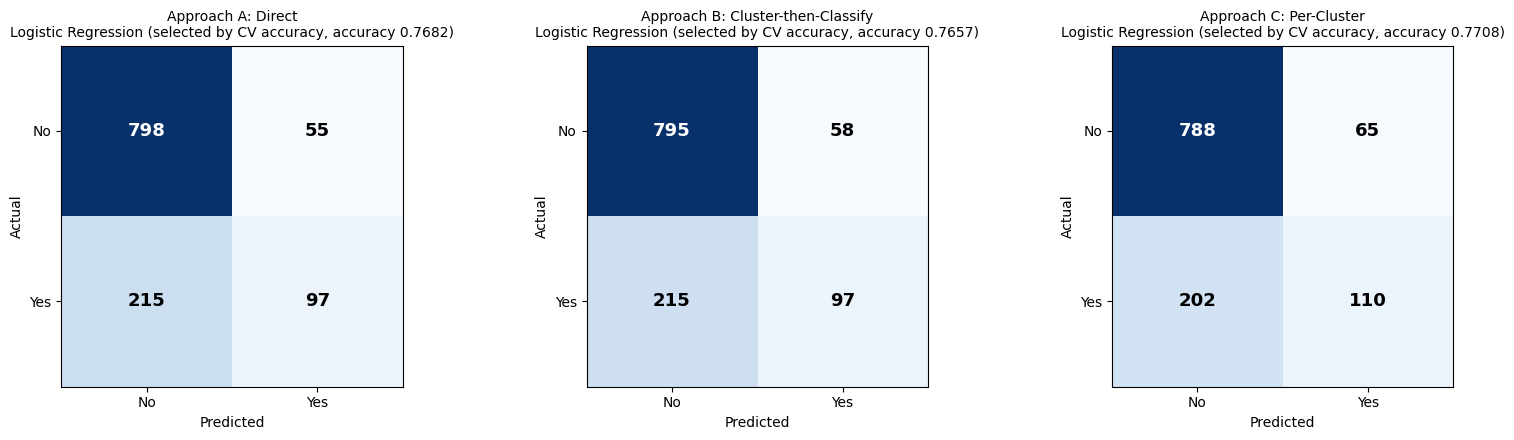

In [52]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_true = y.loc[idx_test].values
approach_titles = {'A': 'Approach A: Direct', 'B': 'Approach B: Cluster-then-Classify', 'C': 'Approach C: Per-Cluster'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, k in zip(axes, 'ABC'):
    name = best_by_approach[k]
    cm = confusion_matrix(y_true, fitted_all[k][name]['preds'])
    ax.imshow(cm, cmap='Blues')
    ax.set_title(f'{approach_titles[k]}\n{name} (selected by CV {SCORING}, accuracy {accuracy_score(y_true, fitted_all[k][name]["preds"]):.4f})', fontsize=10)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['No', 'Yes']); ax.set_yticks([0, 1]); ax.set_yticklabels(['No', 'Yes'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight'); plt.show()


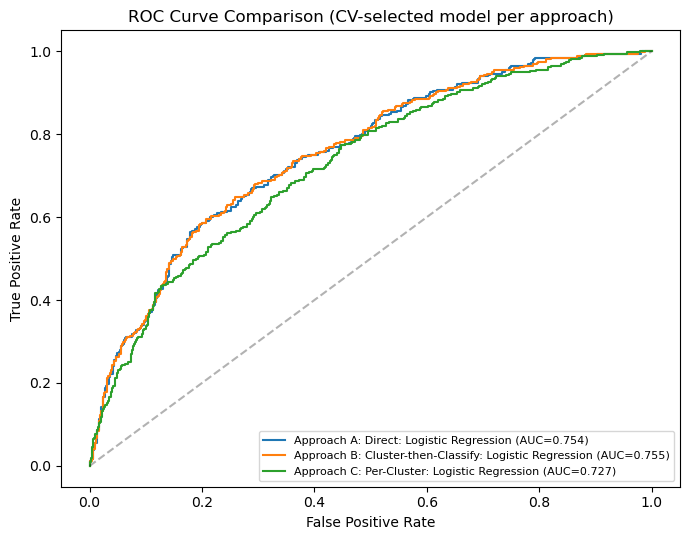

In [53]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for k in 'ABC':
    name = best_by_approach[k]
    fpr, tpr, _ = roc_curve(y_true, fitted_all[k][name]['probs'])
    ax.plot(fpr, tpr, label=f'{approach_titles[k]}: {name} (AUC={auc(fpr, tpr):.3f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate'); ax.set_title('ROC Curve Comparison (CV-selected model per approach)')
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight'); plt.show()


In [54]:
!pip install shap

PART 6: SHAP EXPLAINABILITY (best model of EACH approach)

SHAP is run for the CV-selected model of **Approach A, B and C** so the approaches are explained the same way. For B it also shows how much the cluster feature (its 4 dummy columns combined) contributes compared with the original health/lifestyle features. For C the SHAP values of the four per-cluster models are stacked. Note: mean |SHAP| values come from different model types, so compare *rankings* across approaches, not raw magnitudes.


Background dataset has 4659 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=4659 when initializing the masker.


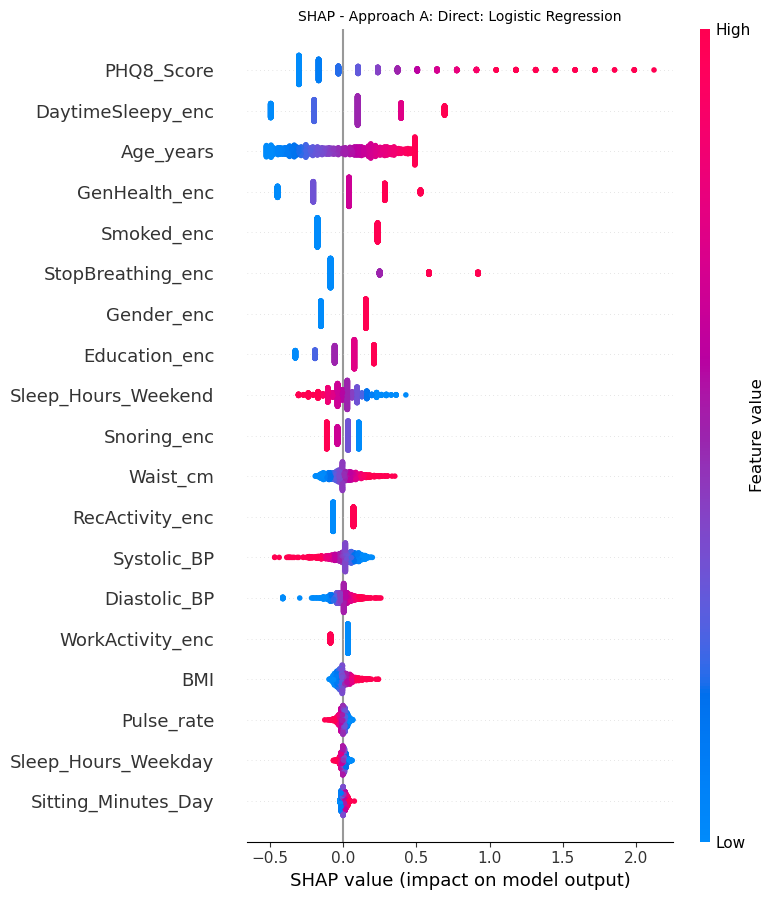

Background dataset has 4659 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=4659 when initializing the masker.


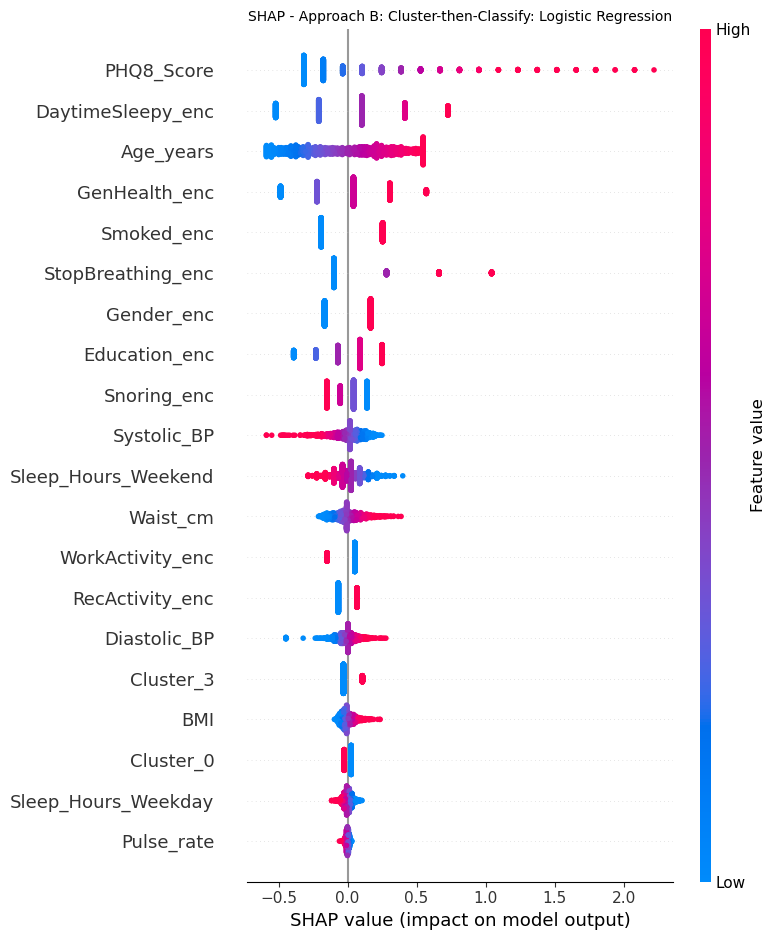

Background dataset has 2201 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2201 when initializing the masker.


Background dataset has 700 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=700 when initializing the masker.


Background dataset has 988 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=988 when initializing the masker.


Background dataset has 770 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=770 when initializing the masker.


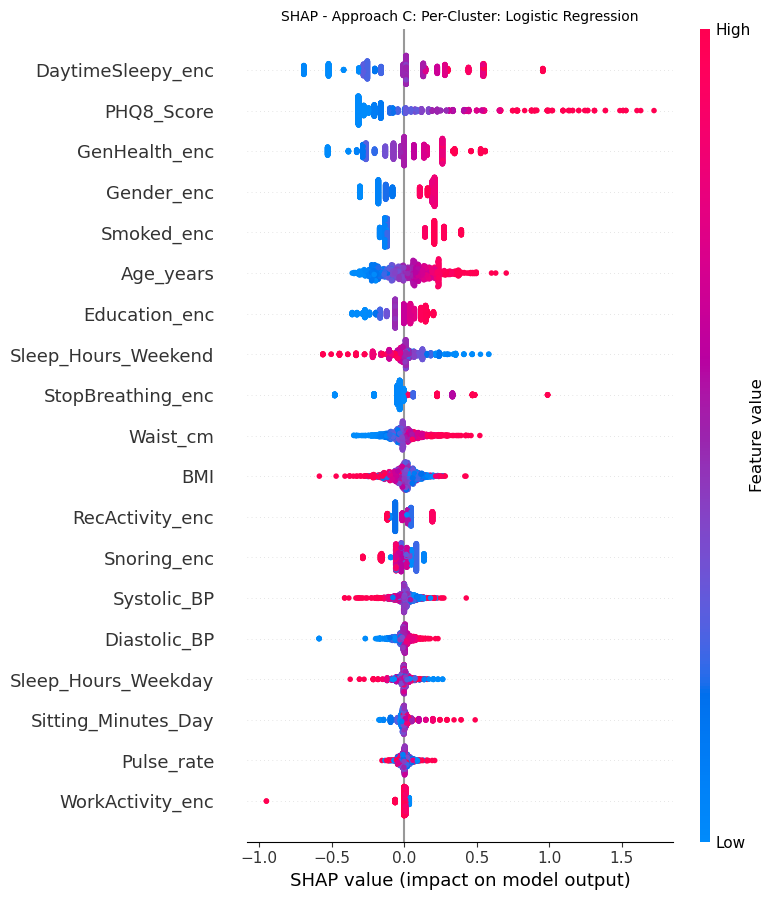

Mean |SHAP| per feature. Columns: {'A': 'Logistic Regression', 'B': 'Logistic Regression', 'C': 'Logistic Regression'}


,A,B,C
Feature,,,
PHQ8_Score,0.3153,0.3296,0.2674
DaytimeSleepy_enc,0.2983,0.3132,0.2677
Age_years,0.2681,0.2998,0.1514
GenHealth_enc,0.2108,0.2278,0.1836
Smoked_enc,0.1997,0.2162,0.1700
StopBreathing_enc,0.1731,0.1962,0.0834
Gender_enc,0.1537,0.1667,0.1802
Education_enc,0.1385,0.1649,0.1072
Snoring_enc,0.0751,0.0997,0.0579


In [55]:
import shap

TREE_MODELS = (RandomForestClassifier, XGBClassifier, LGBMClassifier, GradientBoostingClassifier)

def _pos(sv):                      # normalise SHAP output shape to (rows, features) for the positive class
    if isinstance(sv, list):
        return np.asarray(sv[1])
    sv = np.asarray(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv

def shap_for(pipe, X_train_raw, X_explain_raw, max_rows=150, seed=42):
    imputer, scaler, model = pipe.named_steps['imputer'], pipe.named_steps['scaler'], pipe.named_steps['model']
    prep = lambda d: scaler.transform(imputer.transform(d))      # same filling + scaling the model saw
    Xe = pd.DataFrame(prep(X_explain_raw), columns=X_explain_raw.columns, index=X_explain_raw.index)
    Xt = prep(X_train_raw)
    if isinstance(model, TREE_MODELS):
        sv = _pos(shap.TreeExplainer(model).shap_values(Xe))
    elif isinstance(model, LogisticRegression):
        sv = _pos(shap.LinearExplainer(model, Xt).shap_values(Xe))
    else:                          # SVM / KNN: model-agnostic explainer on a random sample of test rows
        Xe = Xe.sample(min(max_rows, len(Xe)), random_state=seed)
        sv = _pos(shap.KernelExplainer(lambda d: model.predict_proba(d)[:, 1], shap.kmeans(Xt, 10)).shap_values(Xe.values, nsamples=100))
    return sv, Xe

shap_out = {}
for k in 'ABC':
    name, f = best_by_approach[k], fitted_all[k][best_by_approach[k]]
    if k == 'C':                   # stack the four per-cluster models
        parts = []
        for c, pipe in f['cluster_estimators'].items():
            tr_idx = idx_train[df.loc[idx_train, 'Cluster'].values == c]
            te_idx = idx_test[df.loc[idx_test, 'Cluster'].values == c]
            parts.append(shap_for(pipe, df.loc[tr_idx, base_features], df.loc[te_idx, base_features], max_rows=50))
        sv, Xe = np.vstack([p[0] for p in parts]), pd.concat([p[1] for p in parts])
    else:
        feats = base_features if k == 'A' else features_B
        sv, Xe = shap_for(f['estimator'], df.loc[idx_train, feats], df.loc[idx_test, feats])
    shap_out[k] = (sv, Xe)
    plt.figure()
    shap.summary_plot(sv, Xe, show=False)
    plt.title(f'SHAP - {approach_titles[k]}: {name}', fontsize=10)
    plt.tight_layout(); plt.savefig(f'shap_summary_{k}.png', dpi=150, bbox_inches='tight'); plt.show()

def importance(sv, Xe):
    imp = pd.Series(np.abs(sv).mean(0), index=Xe.columns)
    cl = [c for c in Xe.columns if c in cluster_cols]
    if cl:                         # combine the 4 one-hot cluster columns into one "Cluster" contribution
        pos = [list(Xe.columns).index(c) for c in cl]
        imp = imp.drop(cl)
        imp['Cluster (4 dummies combined)'] = np.abs(sv[:, pos].sum(1)).mean()
    return imp

shap_table = pd.DataFrame({k: importance(*shap_out[k]) for k in 'ABC'})
shap_table = shap_table.loc[shap_table.max(axis=1).sort_values(ascending=False).index]
shap_table.index.name = 'Feature'
shap_table.to_csv('shap_importance.csv')
print('Mean |SHAP| per feature. Columns:', {k: best_by_approach[k] for k in 'ABC'})
shap_table.round(4)


In [56]:
top3 = {k: ', '.join(shap_table[k].dropna().sort_values(ascending=False).head(3).index) for k in 'ABC'}
b_rank = int(shap_table['B'].dropna().rank(ascending=False)['Cluster (4 dummies combined)'])
b_n = int(shap_table['B'].notna().sum())
display(Markdown(f"""**Discussion (generated from the SHAP table):**
- Top 3 features -> A ({best_by_approach['A']}): {top3['A']}; B ({best_by_approach['B']}): {top3['B']}; C ({best_by_approach['C']}): {top3['C']}.
- In Approach B the combined **Cluster** feature ranks **{b_rank} of {b_n}** by mean |SHAP|. A low rank means the cluster label adds little that the original features do not already carry, which is consistent with the small effects in 4.7.
"""))


**Discussion (generated from the SHAP table):**
- Top 3 features -> A (Logistic Regression): PHQ8_Score, DaytimeSleepy_enc, Age_years; B (Logistic Regression): PHQ8_Score, DaytimeSleepy_enc, Age_years; C (Logistic Regression): DaytimeSleepy_enc, PHQ8_Score, GenHealth_enc.
- In Approach B the combined **Cluster** feature ranks **16 of 20** by mean |SHAP|. A low rank means the cluster label adds little that the original features do not already carry, which is consistent with the small effects in 4.7.



 PART 7: FAIRNESS EVALUATION


In [57]:
ab = all_results[all_results['Approach'].str[0].isin(['A', 'B'])]      # A and B share identical CV folds/rows, so their CV scores are comparable
final_row = ab.loc[ab['CV_Score'].idxmax()]
final_k, final_model = final_row['Approach'][0], final_row['Model']
print(f'Fairness is evaluated on the best CV-scored model among the global approaches A and B: Approach {final_k}, {final_model}')

meta = df.loc[idx_test, ['Gender', 'Age_years']].copy()
meta['y_true'] = y.loc[idx_test].values
meta['y_pred'] = fitted_all[final_k][final_model]['preds']
meta['AgeGroup'] = np.where(meta['Age_years'] < 40, 'Under 40', '40 and above')

fairness_rows = []
for group_type, col in [('Gender', 'Gender'), ('Age', 'AgeGroup')]:
    for grp in meta[col].unique():
        sub = meta[meta[col] == grp]
        fairness_rows.append({
            'Group_Type': group_type, 'Group': grp, 'N': len(sub), 'Positive_Rate': sub.y_true.mean(),
            'Accuracy': accuracy_score(sub.y_true, sub.y_pred),
            'Precision': precision_score(sub.y_true, sub.y_pred, zero_division=0),
            'Recall': recall_score(sub.y_true, sub.y_pred, zero_division=0),
            'F1': f1_score(sub.y_true, sub.y_pred, zero_division=0)})

fairness_df = pd.DataFrame(fairness_rows).round(4)
fairness_df.to_csv('fairness_results.csv', index=False)
fairness_df


Fairness is evaluated on the best CV-scored model among the global approaches A and B: Approach A, Logistic Regression


,Group_Type,Group,N,Positive_Rate,Accuracy,Precision,Recall,F1
0,Gender,Male,541,0.2403,0.7856,0.6167,0.2846,0.3895
1,Gender,Female,624,0.2917,0.7532,0.6522,0.3297,0.4380
2,Age,40 and above,724,0.3356,0.7238,0.6720,0.3457,0.4565
3,Age,Under 40,441,0.1565,0.8413,0.4815,0.1884,0.2708


In [58]:
def recall_gap(group_type):
    s = fairness_df[fairness_df.Group_Type == group_type].set_index('Group')
    lo, hi = s['Recall'].idxmin(), s['Recall'].idxmax()
    return lo, hi, s.loc[lo, 'Recall'], s.loc[hi, 'Recall']

fair_parts = []
for g in ['Gender', 'Age']:
    lo, hi, r_lo, r_hi = recall_gap(g)
    flag = 'a gap worth flagging' if (r_hi - r_lo) > 0.10 else 'a small gap'
    fair_parts.append(f"{g}: recall is lowest for '{lo}' ({r_lo:.2f}) and highest for '{hi}' ({r_hi:.2f}), {flag}")
fairness_text = '; '.join(fair_parts) + '.'
display(Markdown(f"""**Fairness finding (generated from the table above):** {fairness_text}
Accuracy differences between groups partly reflect different base rates (see `Positive_Rate`): a group with fewer true cases gets higher accuracy almost automatically, so recall is the fairer comparison here.
"""))


**Fairness finding (generated from the table above):** Gender: recall is lowest for 'Male' (0.28) and highest for 'Female' (0.33), a small gap; Age: recall is lowest for 'Under 40' (0.19) and highest for '40 and above' (0.35), a gap worth flagging.
Accuracy differences between groups partly reflect different base rates (see `Positive_Rate`): a group with fewer true cases gets higher accuracy almost automatically, so recall is the fairer comparison here.



 PART 8: FINAL RESULTS EXPORT (Excel)


In [59]:
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter
from openpyxl.drawing.image import Image as XLImage

cluster_profile = df.groupby('Cluster').agg(Count=('SEQN','count'), Avg_Age=('Age_years','mean'),
    Avg_BMI=('BMI','mean'), Avg_Waist=('Waist_cm','mean'), Avg_Systolic_BP=('Systolic_BP','mean'),
    Sleep_Trouble_Rate=('Target_Binary','mean')).round(2).reset_index()

def fmt(r, m):
    return f"{r[m]:.4f} (Approach {r['Approach'][0]}, {r['Model']})"
best_acc_row = all_results.loc[all_results['Accuracy'].idxmax()]
best_f1_row = all_results.loc[all_results['F1'].idxmax()]
final_shap_top = ', '.join(shap_table[final_k].dropna().sort_values(ascending=False).head(3).index)

summary_rows = pd.DataFrame([
    ['Research Question', 'Does clustering before classification improve sleep-trouble prediction?'],
    ['Target', 'Doctor-told sleep trouble (SLQ050, self-reported); NOT a clinically confirmed sleep disorder'],
    ['Majority-class baseline accuracy', f'{majority_acc:.4f}'],
    ['Selection rule', f'Best cross-validated {SCORING} on training data, per approach (test set not used for selection)'],
    ['Selected model per approach', '; '.join(f"{k}: {best_by_approach[k]}" for k in 'ABC')],
    ['Features', f'{len(base_features)} low-cost features ({len(original_features)} original + {len(selfreport_features)} self-report questionnaire items)'],
    ['Clustering', 'Hierarchical (Ward), k=4, fitted on training rows; test rows assigned to nearest centroid'],
    ['Decision threshold', f'Tuned on out-of-fold training predictions for {SCORING}; selected models: ' + '; '.join(f"{k}: {bt.loc[k, 'Threshold']}" for k in 'ABC')],
    ['Highest test Accuracy (reported, not used for selection)', fmt(best_acc_row, 'Accuracy')],
    ['Highest test F1 (reported, not used for selection)', fmt(best_f1_row, 'F1')],
    ['Key Finding (paired bootstrap)', key_finding_text],
    ['Fairness Finding', fairness_text],
    ['Top SHAP Features (final model)', final_shap_top],
], columns=['Metric', 'Value'])

with pd.ExcelWriter('Sleep_Disorder_Results.xlsx', engine='openpyxl') as writer:
    all_results.drop(columns=['Confusion_Matrix'], errors='ignore').to_excel(writer, sheet_name='All Results (A,B,C)', index=False)
    best_table.to_excel(writer, sheet_name='Best per Approach', index=False)
    organized.to_excel(writer, sheet_name='Comparison A vs B vs C')
    sig_df.drop(columns='Text').round(4).to_excel(writer, sheet_name='Bootstrap Significance', index=False)
    fairness_df.to_excel(writer, sheet_name='Fairness Check', index=False)
    cluster_profile.to_excel(writer, sheet_name='Cluster Profiles', index=False)
    validation_summary.to_excel(writer, sheet_name='Cluster Validation', index=False)
    shap_table.reset_index().to_excel(writer, sheet_name='SHAP Importance', index=False)
    summary_rows.to_excel(writer, sheet_name='Summary', index=False)

wb = load_workbook('Sleep_Disorder_Results.xlsx')
header_fill = PatternFill(start_color='1F4E78', end_color='1F4E78', fill_type='solid')
header_font = Font(bold=True, color='FFFFFF')
for sheet in wb.sheetnames:
    ws = wb[sheet]
    for cell in ws[1]:
        cell.fill = header_fill; cell.font = header_font
        cell.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)
    for col_cells in ws.columns:
        length = max((len(str(c.value)) if c.value is not None else 0) for c in col_cells)
        ws.column_dimensions[get_column_letter(col_cells[0].column)].width = min(max(length+3, 10), 45)
    ws.freeze_panes = 'B2'

ws_charts = wb.create_sheet('Charts')
for img, anchor in [('dendrogram_silhouette.png', 'L1'), ('confusion_matrices.png', 'A1'), ('roc_curves.png', 'A28'), ('shap_summary_A.png', 'A55'),
                    ('shap_summary_B.png', 'A95'), ('shap_summary_C.png', 'A135')]:
    ws_charts.add_image(XLImage(img), anchor)
wb.save('Sleep_Disorder_Results.xlsx')
print('Saved Sleep_Disorder_Results.xlsx with sheets:', wb.sheetnames)


Saved Sleep_Disorder_Results.xlsx with sheets: ['All Results (A,B,C)', 'Best per Approach', 'Comparison A vs B vs C', 'Bootstrap Significance', 'Fairness Check', 'Cluster Profiles', 'Cluster Validation', 'SHAP Importance', 'Summary', 'Charts']


PART 9: CONCLUSION

In [60]:
bt = best_table.set_index(best_table['Approach'].str[0])
auc_lo, auc_hi = bt['ROC_AUC'].min(), bt['ROC_AUC'].max()
display(Markdown(f"""### Conclusions (generated from the results, so they always match the tables)

1. **Data / target:** NHANES 2017-18, {len(df)} adults, only low-cost, easily collected variables: {len(base_features)} features ({len(original_features)} body/symptom/lifestyle variables + {len(selfreport_features)} self-report questionnaire items such as sleep hours, PHQ-8, general health and sitting time). No laboratory or dietary data. The target is *doctor-told sleep trouble* (self-reported), {y.mean():.1%} positive.
2. **Performance:** the highest test accuracy observed is {best_acc_row['Accuracy']:.4f} ({best_acc_row['Model']}, Approach {best_acc_row['Approach'][0]}), against a majority-class baseline of {majority_acc:.4f}, i.e. {(best_acc_row['Accuracy']-majority_acc)*100:.1f} points above always predicting "No". ROC-AUC of the selected models is {auc_lo:.3f}-{auc_hi:.3f}. Decision thresholds were tuned on out-of-fold training predictions, which trades some recall for accuracy.
3. **Clustering:** hierarchical (Ward) clustering gave 4 overlapping risk profiles with sleep-trouble rates of {rates.min():.0%}-{rates.max():.0%}. Silhouette is weak ({sil_hier:.2f}); agreement with K-Means/GMM is ARI {ari_kmeans:.2f}/{ari_gmm:.2f}; the chi-square association with the target is significant. They are useful descriptive groups, not sharply separated natural clusters.
4. **Three-way comparison (same split, models, grids, CV, imputation, SMOTE, threshold rule):** {key_finding_text}
5. **SHAP:** top features are A: {top3['A']}; B: {top3['B']}; C: {top3['C']}. The combined cluster feature ranks {b_rank} of {b_n} in Approach B.
6. **Fairness (final model, Approach {final_k} {final_model}):** {fairness_text}

**Limitations:** single 80/20 split (mitigated by the bootstrap in 4.7, which only captures test-set sampling noise); the threshold is tuned on the same CV folds used for hyper-parameter tuning, so CV scores are slightly optimistic (the test set is untouched); SMOTE interpolates encoded categorical columns, producing non-integer category values; the target is a self-reported history, not a diagnosis, which caps achievable accuracy with these features.
"""))

### Conclusions (generated from the results, so they always match the tables)

1. **Data / target:** NHANES 2017-18, 5824 adults, only low-cost, easily collected variables: 19 features (14 body/symptom/lifestyle variables + 5 self-report questionnaire items such as sleep hours, PHQ-8, general health and sitting time). No laboratory or dietary data. The target is *doctor-told sleep trouble* (self-reported), 26.8% positive.
2. **Performance:** the highest test accuracy observed is 0.7708 (Logistic Regression, Approach C), against a majority-class baseline of 0.7322, i.e. 3.9 points above always predicting "No". ROC-AUC of the selected models is 0.727-0.755. Decision thresholds were tuned on out-of-fold training predictions, which trades some recall for accuracy.
3. **Clustering:** hierarchical (Ward) clustering gave 4 overlapping risk profiles with sleep-trouble rates of 17%-46%. Silhouette is weak (0.11); agreement with K-Means/GMM is ARI 0.52/0.47; the chi-square association with the target is significant. They are useful descriptive groups, not sharply separated natural clusters.
4. **Three-way comparison (same split, models, grids, CV, imputation, SMOTE, threshold rule):** Compared with the same model in Approach A, adding cluster information (B) -> F1: significantly better for 2/7 models, worse for 2/7; Accuracy: significantly better for 0/7 models, worse for 1/7; ROC_AUC: significantly better for 1/7 models, worse for 1/7. Per-cluster models (C) -> F1: significantly better for 3/7 models, worse for 1/7; Accuracy: significantly better for 0/7 models, worse for 1/7; ROC_AUC: significantly better for 0/7 models, worse for 6/7. Every other difference is within sampling noise.
5. **SHAP:** top features are A: PHQ8_Score, DaytimeSleepy_enc, Age_years; B: PHQ8_Score, DaytimeSleepy_enc, Age_years; C: DaytimeSleepy_enc, PHQ8_Score, GenHealth_enc. The combined cluster feature ranks 16 of 20 in Approach B.
6. **Fairness (final model, Approach A Logistic Regression):** Gender: recall is lowest for 'Male' (0.28) and highest for 'Female' (0.33), a small gap; Age: recall is lowest for 'Under 40' (0.19) and highest for '40 and above' (0.35), a gap worth flagging.

**Limitations:** single 80/20 split (mitigated by the bootstrap in 4.7, which only captures test-set sampling noise); the threshold is tuned on the same CV folds used for hyper-parameter tuning, so CV scores are slightly optimistic (the test set is untouched); SMOTE interpolates encoded categorical columns, producing non-integer category values; the target is a self-reported history, not a diagnosis, which caps achievable accuracy with these features.
